# Lab 4: Non-negative Matrix Factorization

Welcome to the advanced Machine Learning Course.

The objective of this lab session is to code a few regression algorithms and to apply them to synthetic and real datasets.

Please put **"ML - MDS - TD4"** in the mail subject or I might lose your work (which means 0) and send it to ludovic.trautmann@inria.fr

Please label your notebook **"L4_familyname1_familyname2.ipynb"**.

Make sure to put comments in your code. **Raw numerical results or plots without comments will have almost no value in the grading. Please make sure to comment yout results.**

In [2]:
import numpy             as np
import matplotlib.pyplot as plt
import seaborn           as sns
from sklearn.utils       import check_random_state
from sklearn.datasets    import fetch_olivetti_faces

%matplotlib inline
sns.set_context('poster')
sns.set_color_codes()
plot_kwds        = {'alpha' : 0.25, 's' : 80, 'linewidths':0}

dataset          = fetch_olivetti_faces(shuffle=True)
faces            = dataset.data.T #on représente chaque image par une colonne, en accord avec le cours
faces[3523][338] = 1e-2 #l'un des éléments de faces est nul, ce qui bloque la divergence de KL

## NMF

Regularized Froebnius Loss: $\mathcal{L}(W, H) = \frac{1}{2}\|X-W H\|_{F}^{2}+ \frac{\mu}{2}\|H\|_{F}^{2}+\lambda\|H\|_{1}+\frac{\nu}{2}\|W\|_{F}^{2}$

KL Loss : $\mathcal{L}(W,H) = \mathcal{KL}(X, W H)$



Fill in the following NMF class:

In [3]:
class MYNMF():
    
    """
    
    Attributes:                                                                                 
    -----------                                                Default value
    n_components_ : integer,  unknown dimension of W and H   | 20                
    max_iter_     : integer,  maximum number of iterations   | 60
    epsilon_      : float,    epsilon coefficient            | 1e-4
    loss_         : str,      {"Frobenius", "KL"}            | Frobenius
    D_            : np.array, W Matrix factor                | None
    S_            : np.array, H Matrix factor                | None
    D_history     : list,     W Matrix history               | []
    S_history     : list,     H Matrix history               | []
    loss_history  : list,     history of loss                | []
    random_state  : int,      for the random initialization  | 42
    """
    
    def __init__(self, n_components=20, max_iter=200, epsilon = 1e-5, loss = "Frobenius", random_state=42):
        
        self.n_components_ = n_components
        self.max_iter_     = max_iter
        self.epsilon_      = epsilon
        self.loss_         = loss
        self.D_            = None
        self.S_            = None
        self.D_history     = []
        self.S_history     = []
        self.loss_history  = []
        self.random_state  = random_state
        self.components_   = None    # shape (r, p)
        
    def fit_transform(self, data, mu=5e-3,  nu=5e-3, lambd=1e-3):
        
        """ Find the factor matrices D and S for matrix factorization of data
        
        Parameters:
        -----------                                 Default value       
        data  : (p, n) np.arrayData, matrix       | 
        mu    : float, regularization parameter   | 5e-3
        lambd : float, regularization parameter   | 1e-3
        nu    : float, regularization parameter   | 5e-3
        
        Returns:
        -----
        embedding: (p, r) np.array
                    Embedding matrix        
        """        
        #TODO
        # initialization
        (p, n) = np.shape(data)
        rng = np.random.default_rng(self.random_state)
        self.D_ = rng.uniform(size = (p, self.n_components_))
        self.S_ = rng.uniform(size = (self.n_components_, n))
        
        self.D_history.append(self.D_)
        self.S_history.append(self.S_)
        for _ in range(self.max_iter_) :
            
            if self.loss_ == "Frobenius" :
                denom_d = (self.D_ @ self.S_ @ self.S_.T + nu * self.D_)
                self.D_ = self.D_ * ((data @ self.S_.T)/(np.maximum(denom_d, self.epsilon_)))
                
                denom_s = (self.D_.T @self.D_ @ self.S_ + mu * self.S_ + lambd * np.ones((self.n_components_, n)))
                self.S_ = self.S_ * (self.D_.T @ data)/(np.maximum(denom_s, self.epsilon_))
                
                loss_value = (1/2)*np.linalg.norm(data - self.D_ @ self.S_, 'fro')**2 + (mu/2)*np.linalg.norm(self.S_, 'fro')**2 + lambd * np.sum(np.abs(self.S_)) + (nu/2)*np.linalg.norm(self.D_, 'fro')**2
                                                
            if self.loss_ == "KL" : 
                self.D_ = self.D_ * ((data /(np.maximum(self.D_ @ self.S_, self.epsilon_))) @ self.S_.T /(np.maximum(np.sum(self.S_, axis=1), self.epsilon_)))
                self.S_ = self.S_ * (self.D_.T @ (data / (np.maximum(self.D_ @ self.S_ , self.epsilon_))) / (np.maximum(np.sum(self.D_, axis=0)[:, np.newaxis] , self.epsilon_)))
                recons = self.D_ @ self.S_
                term = np.zeros_like(data, dtype=float)
                term = data * np.log(data / np.maximum(recons, self.epsilon_))
                loss_value = np.sum(term - data + recons )
                
            self.D_history.append(self.D_)
            self.S_history.append(self.S_)
            self.loss_history.append(loss_value)
                
        return self.D_
        

    def predict_label(self, X):
        """ Predict labels for X : cluster hard-assignment
        First, we start by normalizing the norm of the dictionary elements, so that the euclidian norm = 1, 
        and we multiply the associated row in the S matrix to preserve the factorization DS = X. 
        Then, we find the highest coefficient for each image, and we use the index of the maximum as clustering label.
        
        Parameters:
        -----------
        X : (n, p) np.array, data matrix
        
        Returns:
        -----
        label assignment : (p, ) np.array, Its elements are the predicted classes, from 0 to r-1
        """
        #TODO
        # poids le plus élevé
        norms = np.maximum(np.linalg.norm(self.D_, axis=0), self.epsilon_)
        new_D_ = self.D_ / norms[np.newaxis, :]
        new_S_ = self.S_ * norms[:, np.newaxis]

        assignment = np.array([np.argmax(new_S_[:, i]) for i in range(np.shape(X)[1])])
        return assignment
        
        
    def predict_proba(self, X):
        """ Predict probabilities of different classes for X :  cluster soft-assignment
        
        Parameters:
        -----------
        X: (n, p) np.array
            New data matrix
        
        Returns:
        -----
        label_assignment : (p, r) np.array
                          Its elements are the probabilities for different classes
        """
        #TODO
        # par rapport aux poids 
        norms = np.maximum(np.linalg.norm(self.D_, axis=0), self.epsilon_)
        new_D_ = self.D_ / norms[np.newaxis, :]
        new_S_ = self.S_ * norms[:, np.newaxis]
        label_assignment = (new_S_ / new_S_.sum(axis = 0)).T
        return label_assignment

# Hyperparameter optimization

### Regularization parameter : mu

Text(0.5, 1.0, 'Normalized distance')

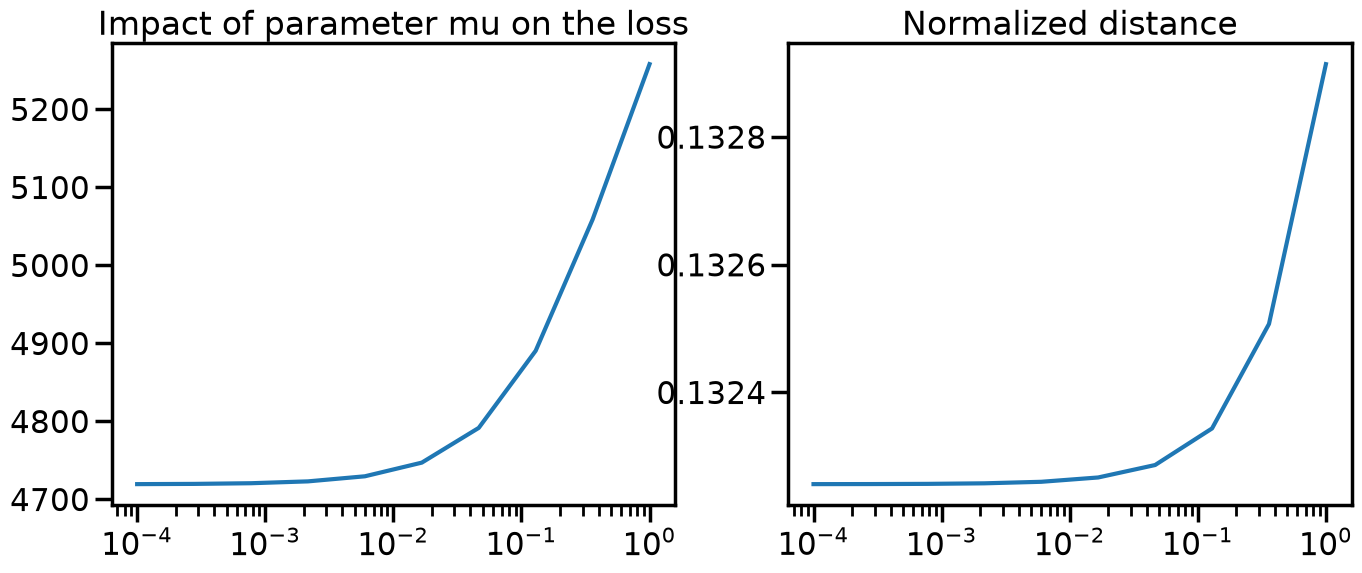

In [3]:
#TODO : find best mu

possible_mu = np.logspace(-4, 0, num = 10)
normalized_distance = []
loss = []

for mu in possible_mu:
    mynmf = MYNMF()
    mynmf.fit_transform(data = faces, mu = mu)
    normalized_distance.append(np.linalg.norm(faces - mynmf.D_ @ mynmf.S_, 'fro')/np.linalg.norm(faces))
    loss.append(mynmf.loss_history[-1])

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].set_xscale("log")
ax[0].plot(possible_mu, loss)
ax[0].set_title("Impact of parameter mu on the loss")

ax[1].set_xscale("log")
ax[1].plot(possible_mu, normalized_distance)
ax[1].set_title("Normalized distance")

**Comments:** 

The smaller $\mu$, the smaller the loss. It makes sense: what we plot is the loss, and it contains a term in $ + \frac{\mu}{2}\|H\|_{F}^{2}$. So if we increase $\mu$, we also increase the loss. 

We also notice that the smaller $\mu$, the smaller the distance between X and its reconstruction. With a small $\mu$, we mainly focus on the quality of the reconstruction (minimize distance between X and the reconstruction), and not necessarily on reducing the complexity of the reconstruction: we might have a very good reconstruction, but that is really overfitted on the X matrix. 

### Regularization parameter : nu

Text(0.5, 1.0, 'Normalized distance')

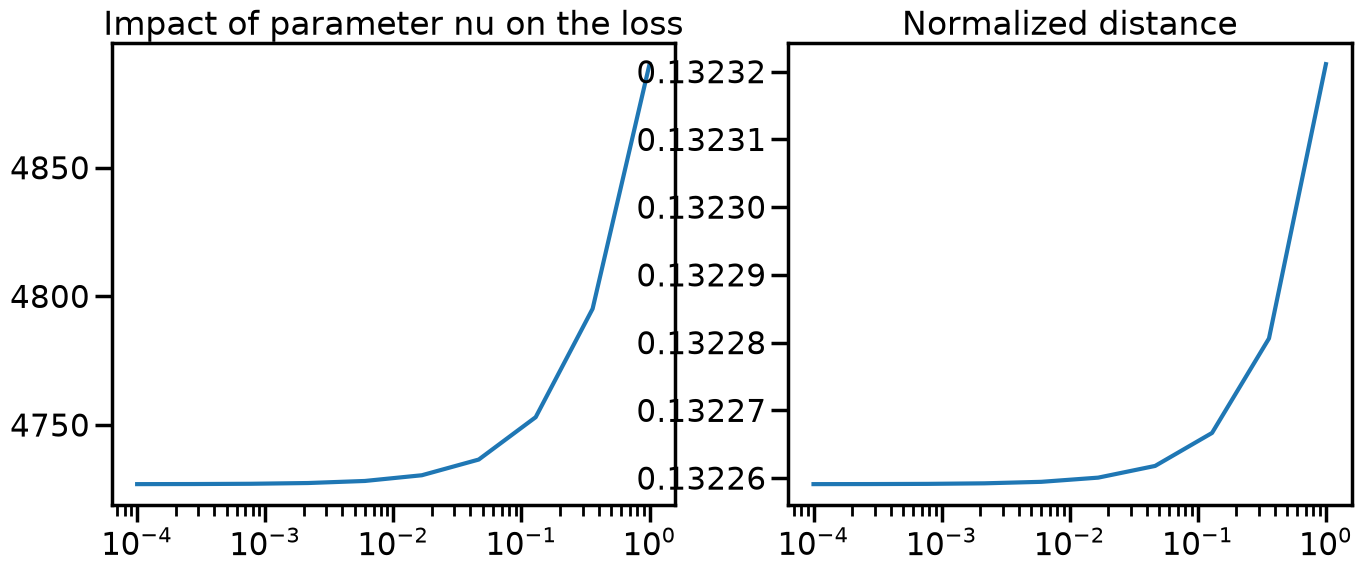

In [4]:

#TODO : find best nu
possible_nu = np.logspace(-4, 0, num = 10)
loss = []
normalized_distance = []

for nu in possible_nu:
    mynmf = MYNMF()
    mynmf.fit_transform(data = faces, nu = nu)
    normalized_distance.append(np.linalg.norm(faces - mynmf.D_ @ mynmf.S_, 'fro')/np.linalg.norm(faces))
    loss.append(mynmf.loss_history[-1])
    
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].set_xscale("log")
ax[0].plot(possible_nu, loss)
ax[0].set_title("Impact of parameter nu on the loss")

ax[1].set_xscale("log")
ax[1].plot(possible_nu, normalized_distance)
ax[1].set_title("Normalized distance")

**Comments:** The smaller $\nu$, the smaller the loss. It makes sense: what we plot is the loss, and it contains a term in $ +\frac{\nu}{2}\|W\|_{F}^{2}$. So if we increase $\nu$, we also increase the loss, even for a fixed W matrix. 

The parameter $\nu$ doesn't really impact the distance between the matrix and its reconstruction (variations around $10^{-5}$). 

### Regularization parameter : lambda

Text(0.5, 1.0, 'Normalized distance')

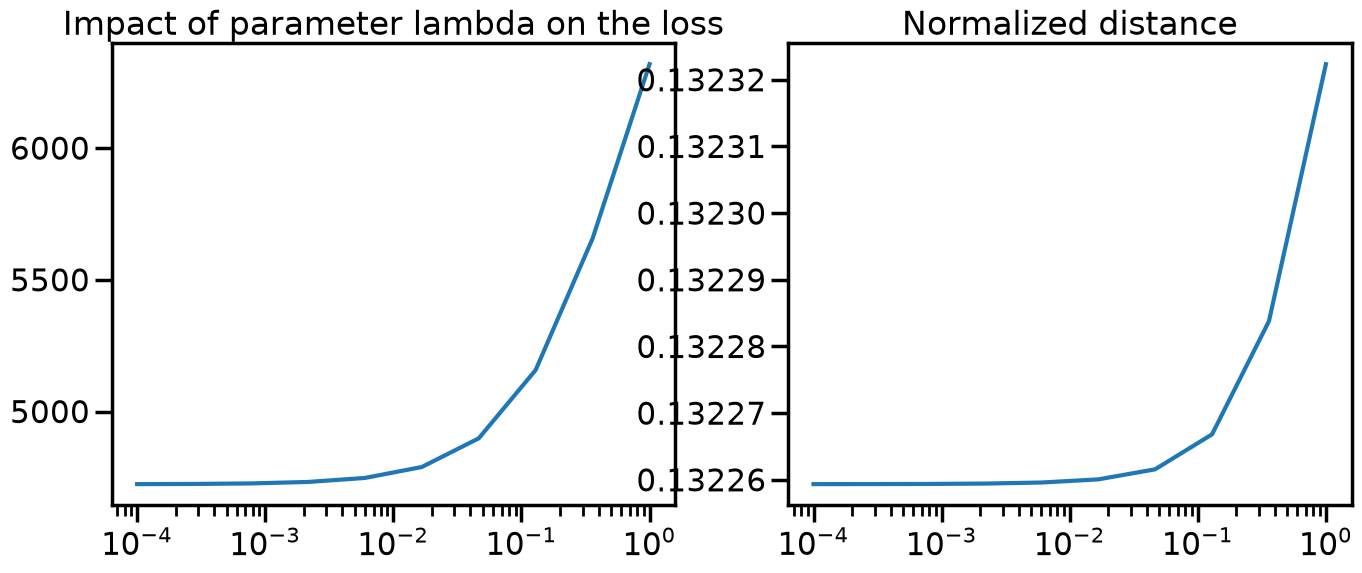

In [5]:
#TODO : find best lambda
possible_lambda = np.logspace(-4, 0, num = 10)
loss = []
normalized_distance = []

for lambd in possible_lambda:
    mynmf = MYNMF()
    mynmf.fit_transform(data = faces, lambd = lambd)
    normalized_distance.append(np.linalg.norm(faces - mynmf.D_ @ mynmf.S_, 'fro')/np.linalg.norm(faces))
    loss.append(mynmf.loss_history[-1])
    

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].set_xscale("log")
ax[0].plot(possible_lambda, loss)
ax[0].set_title("Impact of parameter lambda on the loss")

ax[1].set_xscale("log")
ax[1].plot(possible_lambda, normalized_distance)
ax[1].set_title("Normalized distance")


**Comments:** The smaller $\lambda$, the smaller the loss. It makes sense: what we plot is the loss, and it contains a term in $ + \lambda\|H\|_{1}$. So if we increase $\lambda$, we also increase the loss, even for a fixed H matrix. 

The parameter $\lambda$ doesn't really impact the distance between the matrix and its reconstruction (variations around $10^{-5}$). 

**Overall Comments:** Regularization is relevant when we want to generalize a model without overfitting on the training data. Here, metrics are computed on the training data. To assess of the real impact of the regularization, we should split the matrix between train and test. However, the logic of the lab doesn't incitate to do so. 
**Choice of hyperparameters:** since the reconstruction error is flat for $\mu, \nu, \lambda \leq 10^{-2}$ and only degrades above, we keep the default values ($\mu = \nu = 5\cdot10^{-3}$, $\lambda = 10^{-3}$): they regularize slightly without hurting the reconstruction.



### Number of components

We are going to determine the **optimal number of components** for the factorization by plotting the final loss after 100 epochs for different number of components.
We expect an **elbow curve**, and we will choose the value at the elbow point. Indeed, the higher the number of components is, the more precise the atoms of the dictionary can be, and thus the more precise the reconstructed image will be.
We will find the optimal parameter both for Frobenius and Kullback-Leibler distances.

#### Frobenius

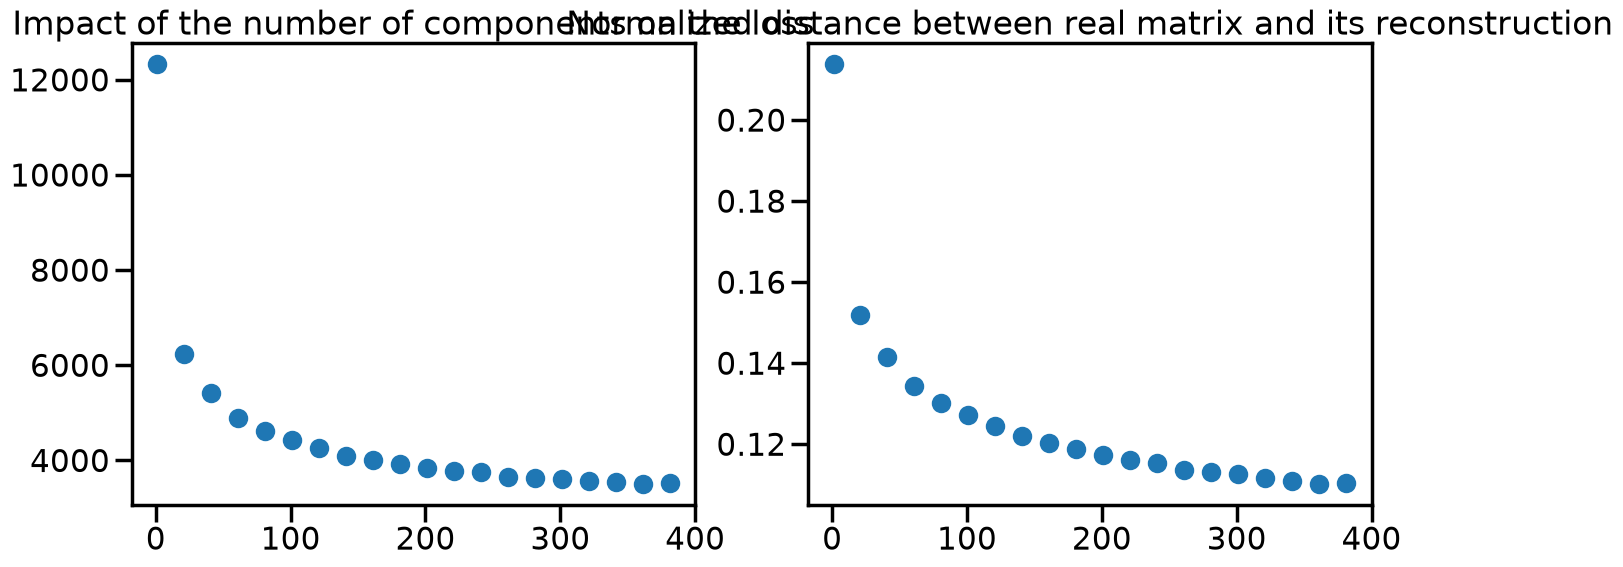

In [6]:
#TODO : plot the loss and normalized distances between S and D for different number of components, for the Frobenius distance AND KL divergence
#Compare and discuss

# ici, S = X et D = WH

(p, n) = np.shape(faces)
number_of_comp = [i for i in range(1, min(n, p), 20)] # mettre un pas cohérent avec les données pour ne pas que ça prenne trop longtemps
loss = []
normalized_distance = []

for num in number_of_comp:
    mynmf = MYNMF(n_components=num, max_iter=100)
    mynmf.fit_transform(data = faces)
    loss.append(mynmf.loss_history[-1])
    normalized_distance.append(np.linalg.norm(faces - mynmf.D_ @ mynmf.S_, 'fro')/np.linalg.norm(faces))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(number_of_comp, loss)
ax[0].set_title("Impact of the number of components on the loss")

ax[1].scatter(number_of_comp, normalized_distance)
ax[1].set_title("Normalized distance between real matrix and its reconstruction")

plt.show()

**Comments:** The elbow value is for 80 number of components. Above this value, the loss doesn't decrease significatively. 

#### KL

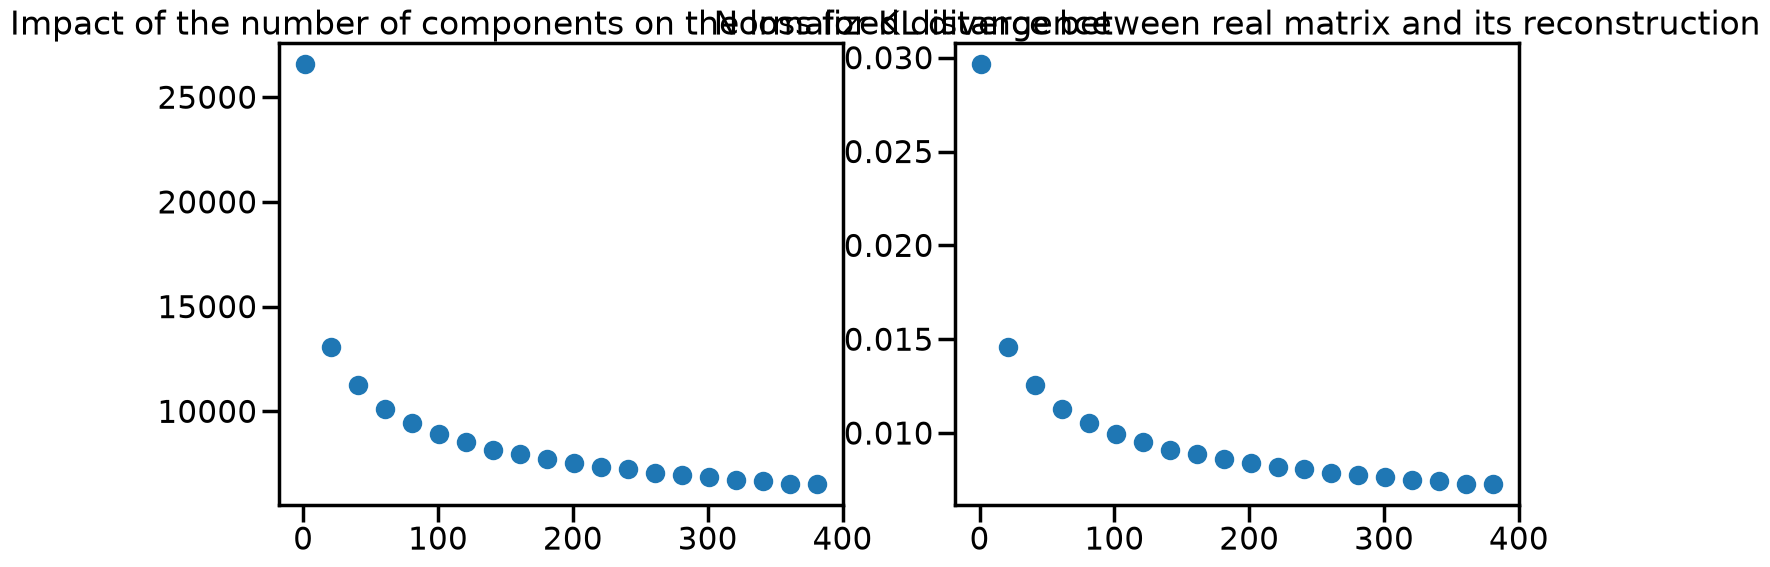

In [7]:
(p, n) = np.shape(faces)
number_of_comp = [i for i in range(1, min(n, p), 20)] 
loss = []
normalized_distance = []

for num in number_of_comp:
    mynmf = MYNMF(n_components=num, max_iter=100, loss="KL")
    mynmf.fit_transform(data = faces)
    loss.append(mynmf.loss_history[-1])
    normalized_distance.append(mynmf.loss_history[-1]/np.sum(faces))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(number_of_comp, loss)
ax[0].set_title("Impact of the number of components on the loss for KL divergence")

ax[1].scatter(number_of_comp, normalized_distance)
ax[1].set_title("Normalized distance between real matrix and its reconstruction")

plt.show()

**Comments:** Same that with the frobenius distance, the elbow value is around 80-100 components. 

## Model training

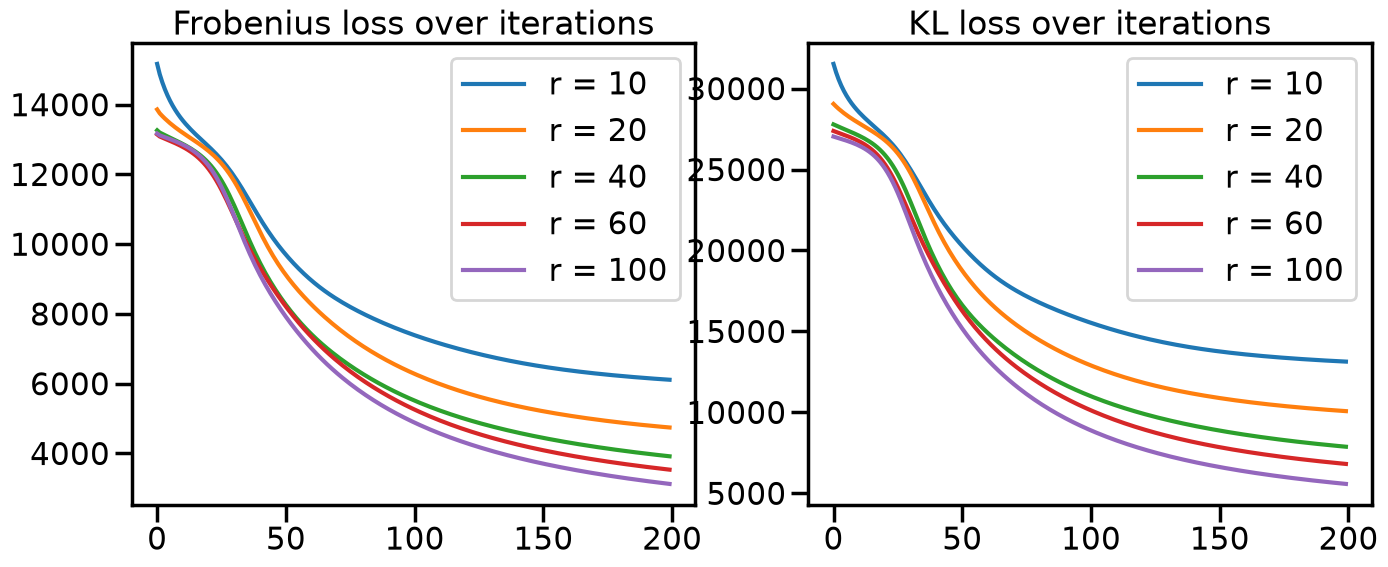

In [22]:
#TODO : Train different models for different number of components with Frobenius loss AND KL divergence, and plot loss function 
number_of_components = [10, 20, 40, 60, 100]

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

for num in number_of_components:
    mynmf = MYNMF(n_components=num)
    mynmf.fit_transform(data = faces)
    ax[0].plot(mynmf.loss_history, label = f"r = {num}")
    
    mynmf = MYNMF(n_components=num, loss = "KL")
    mynmf.fit_transform(data = faces)
    ax[1].plot(mynmf.loss_history, label = f"r = {num}")

ax[0].set_title("Frobenius loss over iterations")
ax[0].legend()

ax[1].set_title("KL loss over iterations")
ax[1].legend()

plt.show()

**Comments:** For both losses, the curves have the same shape: a slow start during the first ~25 iterations, then a fast decrease between ~25 and ~75 iterations, and finally a slow decrease. After 200 iterations the loss is still decreasing, especially for large $r$: the models are not fully converged.

The larger the number of components, the lower the loss at every iteration, which is consistent with the study of the number of components above. However the gap between two curves gets smaller as r increases (10 => 20 is a much larger improvement than 60 => 100), which confirms the elbow behavior.



## First application

For the first application you are going to analyse the face data to give an interpretation of the factorization:

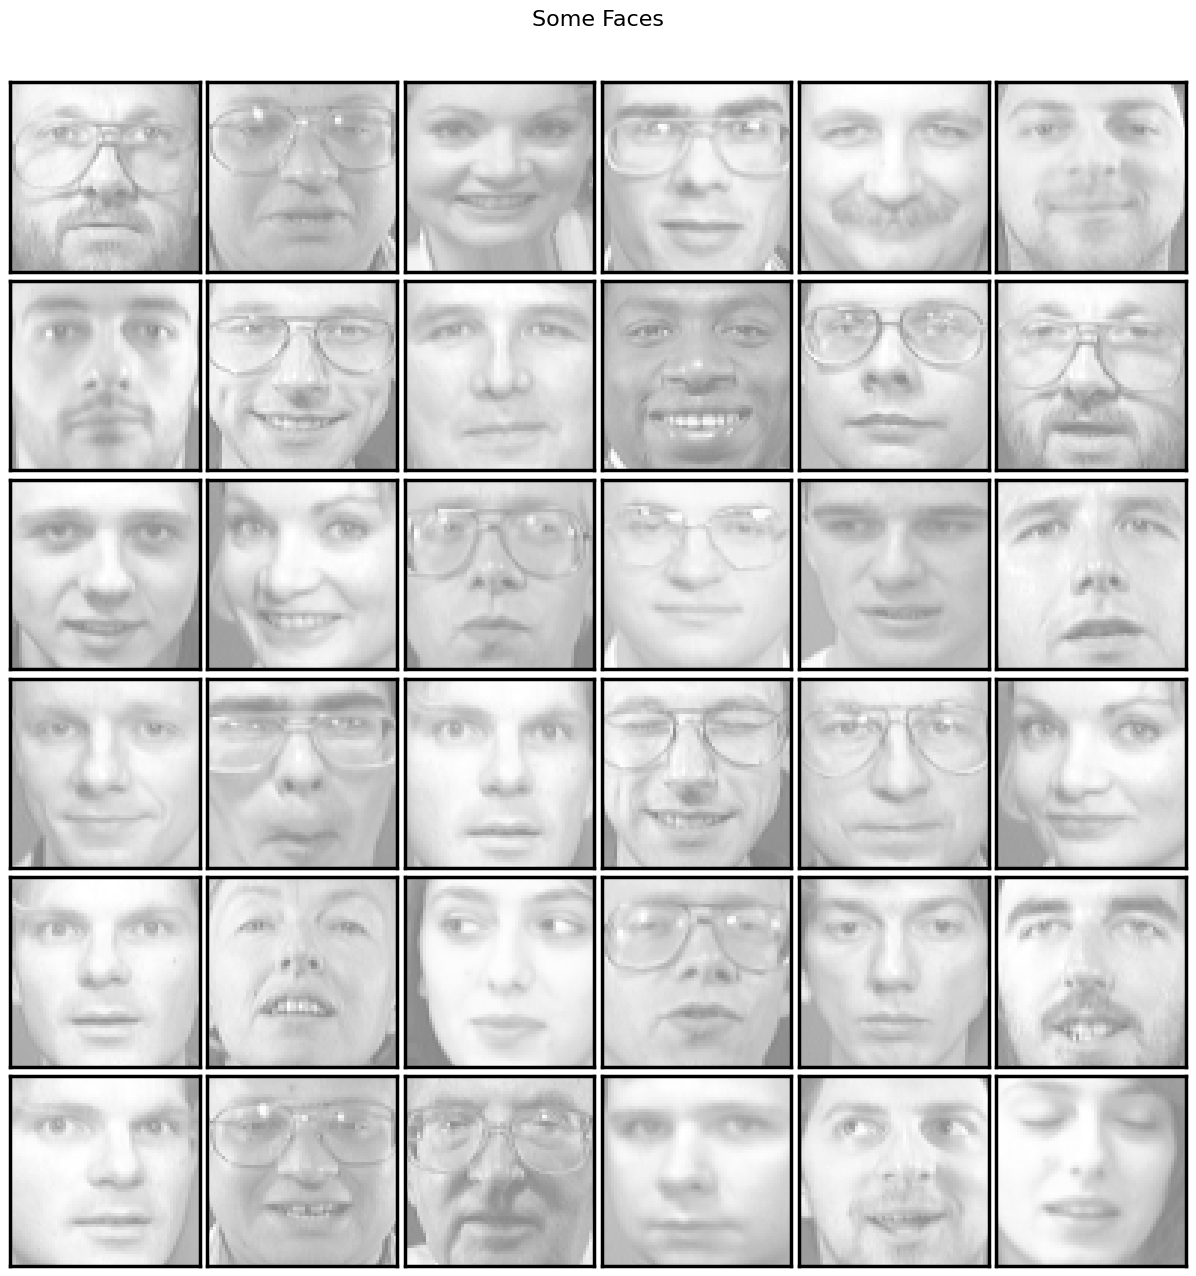

In [5]:
faces = faces.T  # n = 400 flattened images of p = 4096 = 64 x 64 pixels
image_shape = (64, 64)
n_samples, n_features = faces.shape

# global centering
faces_centered = faces - faces.mean(axis=0) # faces.mean(axis=0) : mean of each features over each image (4096 features, 400 people)

# local centering
faces_centered -= faces_centered.mean(axis=1).reshape(n_samples, -1) # mean of each people, over every features

def plot_gallery(images, image_shape, nrow, ncol, title='', cmap=plt.cm.gray):
    
    # fit the nb of images into a square
    n_images = len(images)
    nrows = nrow
    ncols = ncol
    
    # instantiate figure
    fig, axes = plt.subplots(nrows, ncols, figsize=(2. * ncols, 2.26 * nrows))
    fig.suptitle(title, size=16)
    
    axes_for_display = axes.flatten()[:n_images]
    axes_to_blank = axes.flatten()[n_images:]
    
    for idx, comp in enumerate(images):
        ax = axes_for_display[idx]
        vmax = max(comp.max(), -comp.min())
        ax.imshow(comp.reshape(image_shape), cmap=cmap,
                   interpolation='nearest',
                   vmin=-vmax, vmax=vmax)
        ax.set(xticks=(),
               yticks=())
        
    for ax in axes_to_blank:
        ax.axis('off')

    fig.tight_layout()
    fig.subplots_adjust(0.01, 0.05, 0.99, 0.93, 0.04, 0.)  # insert space below the suptitle
    
plot_gallery(title="Some Faces", 
             images=faces[:36], 
             image_shape=image_shape,nrow=6,ncol=6)


### Analysis of the number of components on the reconstruction

#### Reconstruction with Frobenius distance

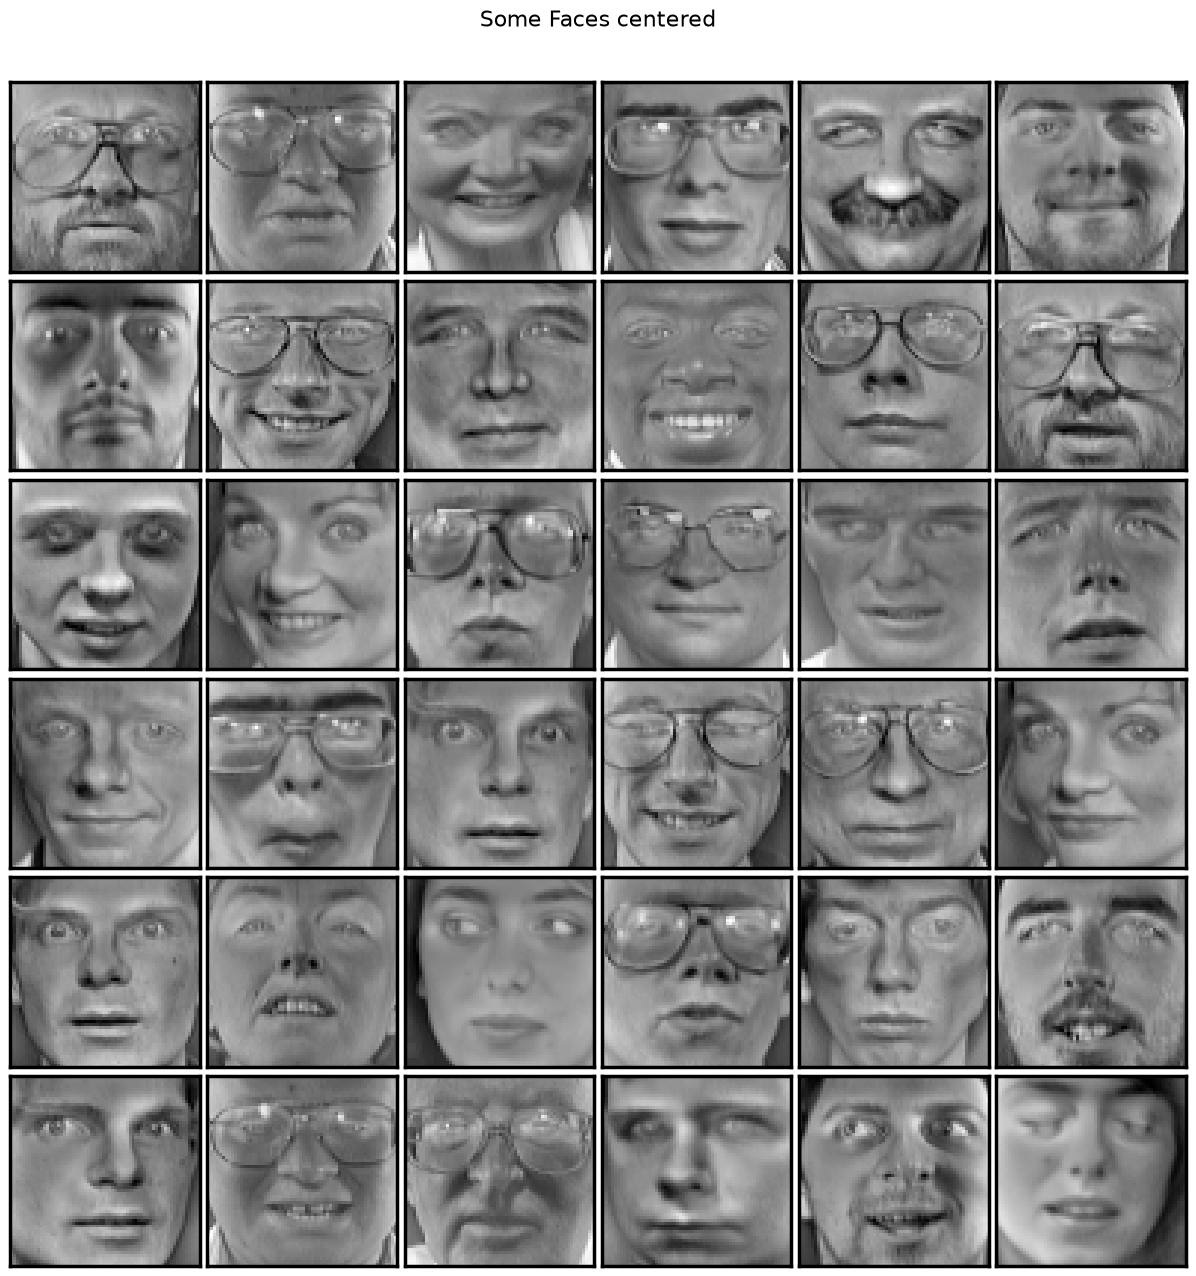

In [10]:
plot_gallery(title="Some Faces centered", 
             images=faces_centered[:36], 
             image_shape=image_shape,nrow=6,ncol=6)

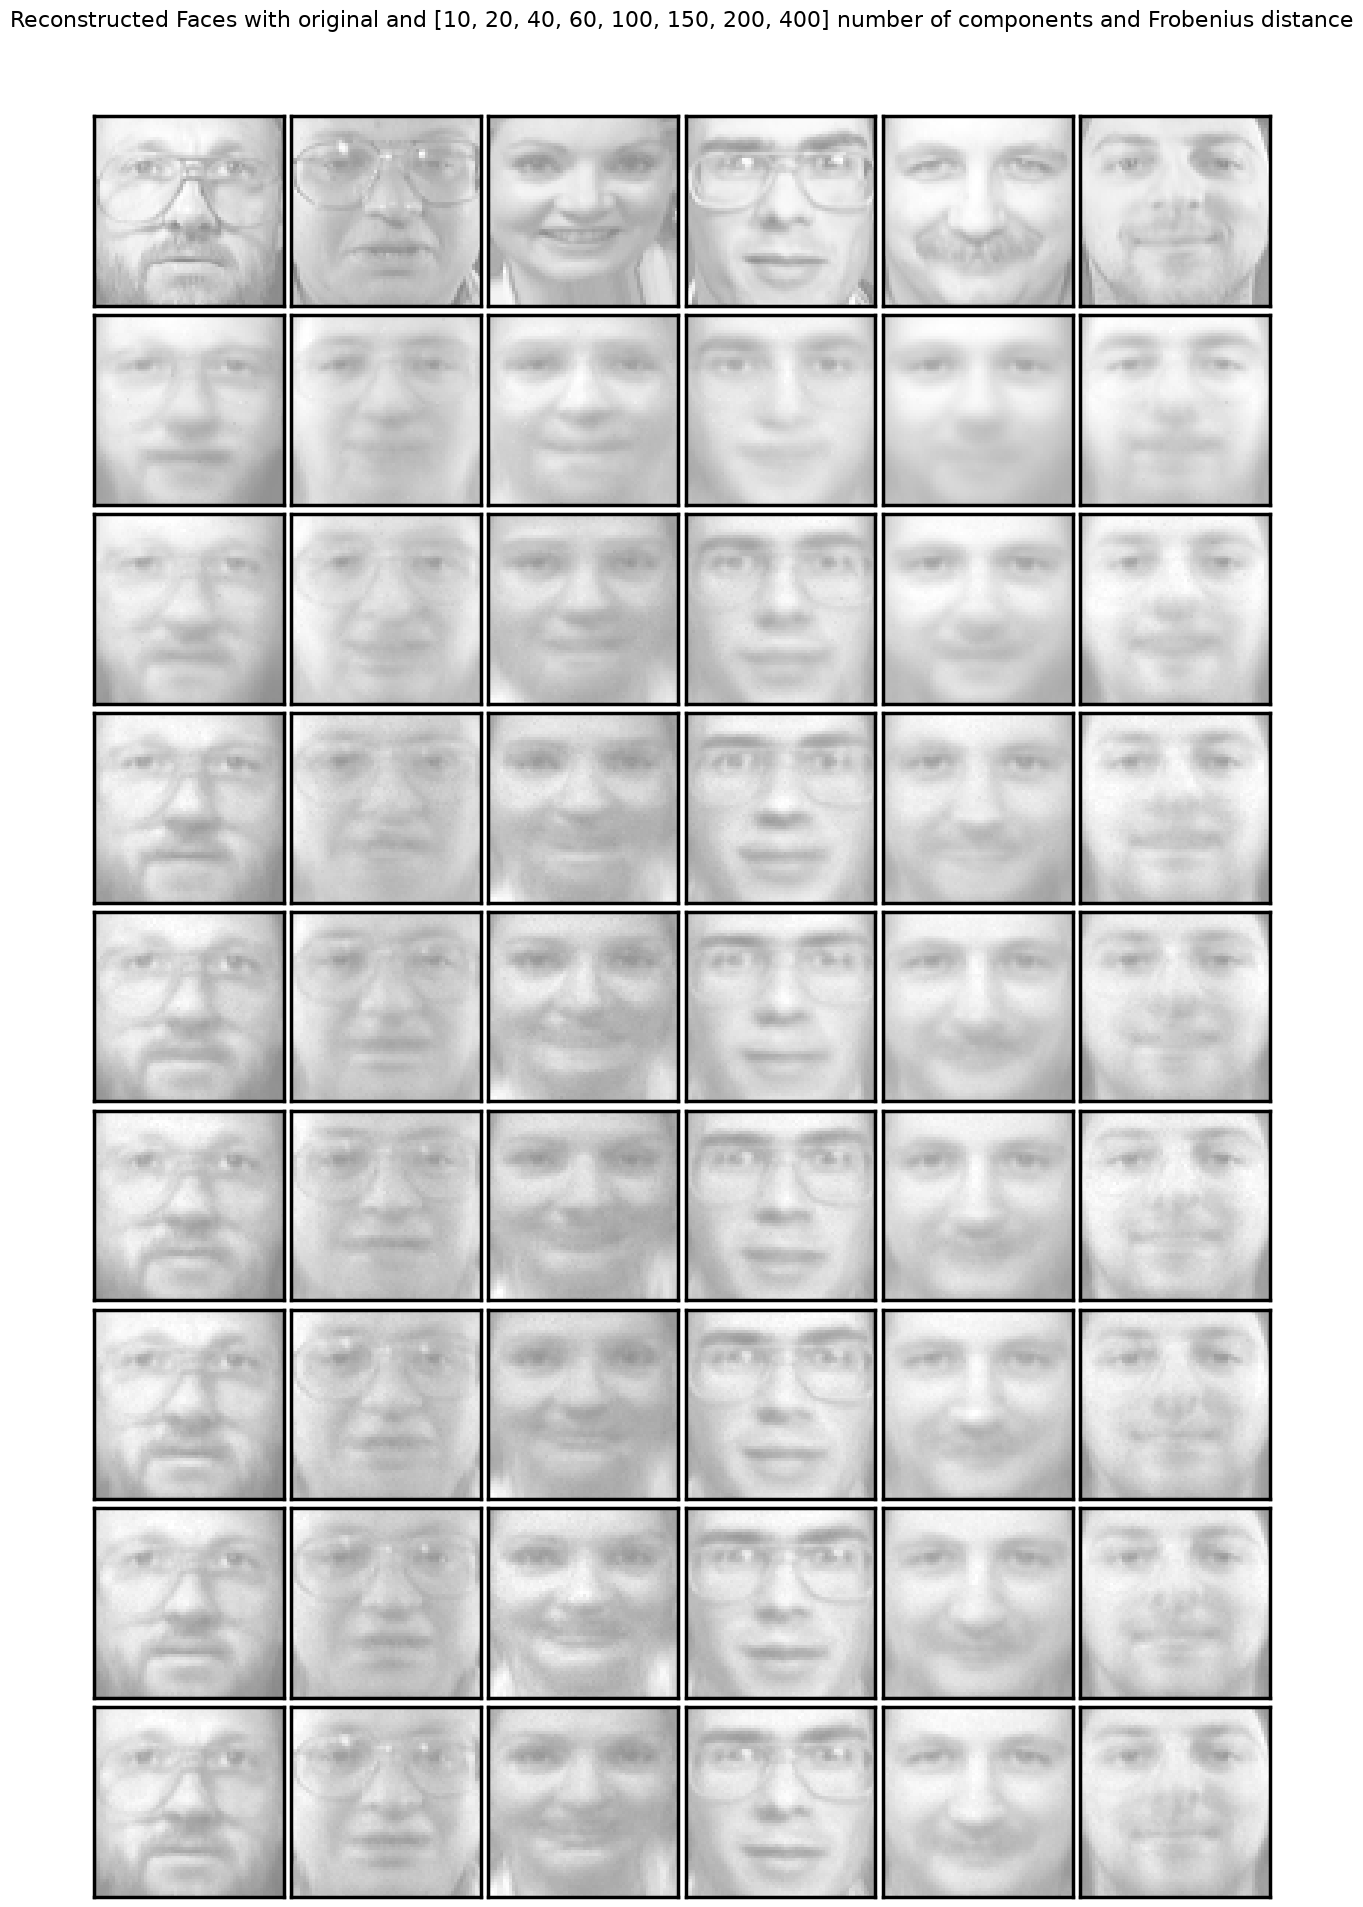

In [11]:
#TODO : plot reconstructed faces for different number of components with Frobenius distance

number_of_components = [10, 20, 40, 60, 100, 150, 200, 400]
reconstructed_images_sample = list(faces[:6])


for num in number_of_components: 
    mynmf = MYNMF(n_components=num)
    mynmf.fit_transform(data = faces.T)
    
    reconstruction = (mynmf.D_ @ mynmf.S_).T
    reconstructed_images_sample += list(reconstruction[:6])
    
plot_gallery(title=f"Reconstructed Faces with original and {number_of_components} number of components and Frobenius distance", 
            images=reconstructed_images_sample, 
            image_shape=image_shape,nrow=9,ncol=6)


**Comments:** It doesn't work on faces_centered, because the faces_centered matrix is not positive anymore (since it's centered). 
On the display just above, the first row corresponds to the original images. Then, each row corresponds to one number of components: [10, 20, 40, 60, 100, 150, 200, 400]. The last row is computed with 400 components: it's the most precise reconstruction we can get. 

The reconstructed images are quite good: even with small number of components, we recognize that images are faces. The higher the number of components, the more we recognize people's features. However, the dataset mostly contains male faces. So with low number of components, the reconstructed face will mostly look like a male. It's the case for the woman if the third column: we recognize it's a woman only when the number of components is above 60.  

#### Reconstruction with Kullback-Leibler divergence

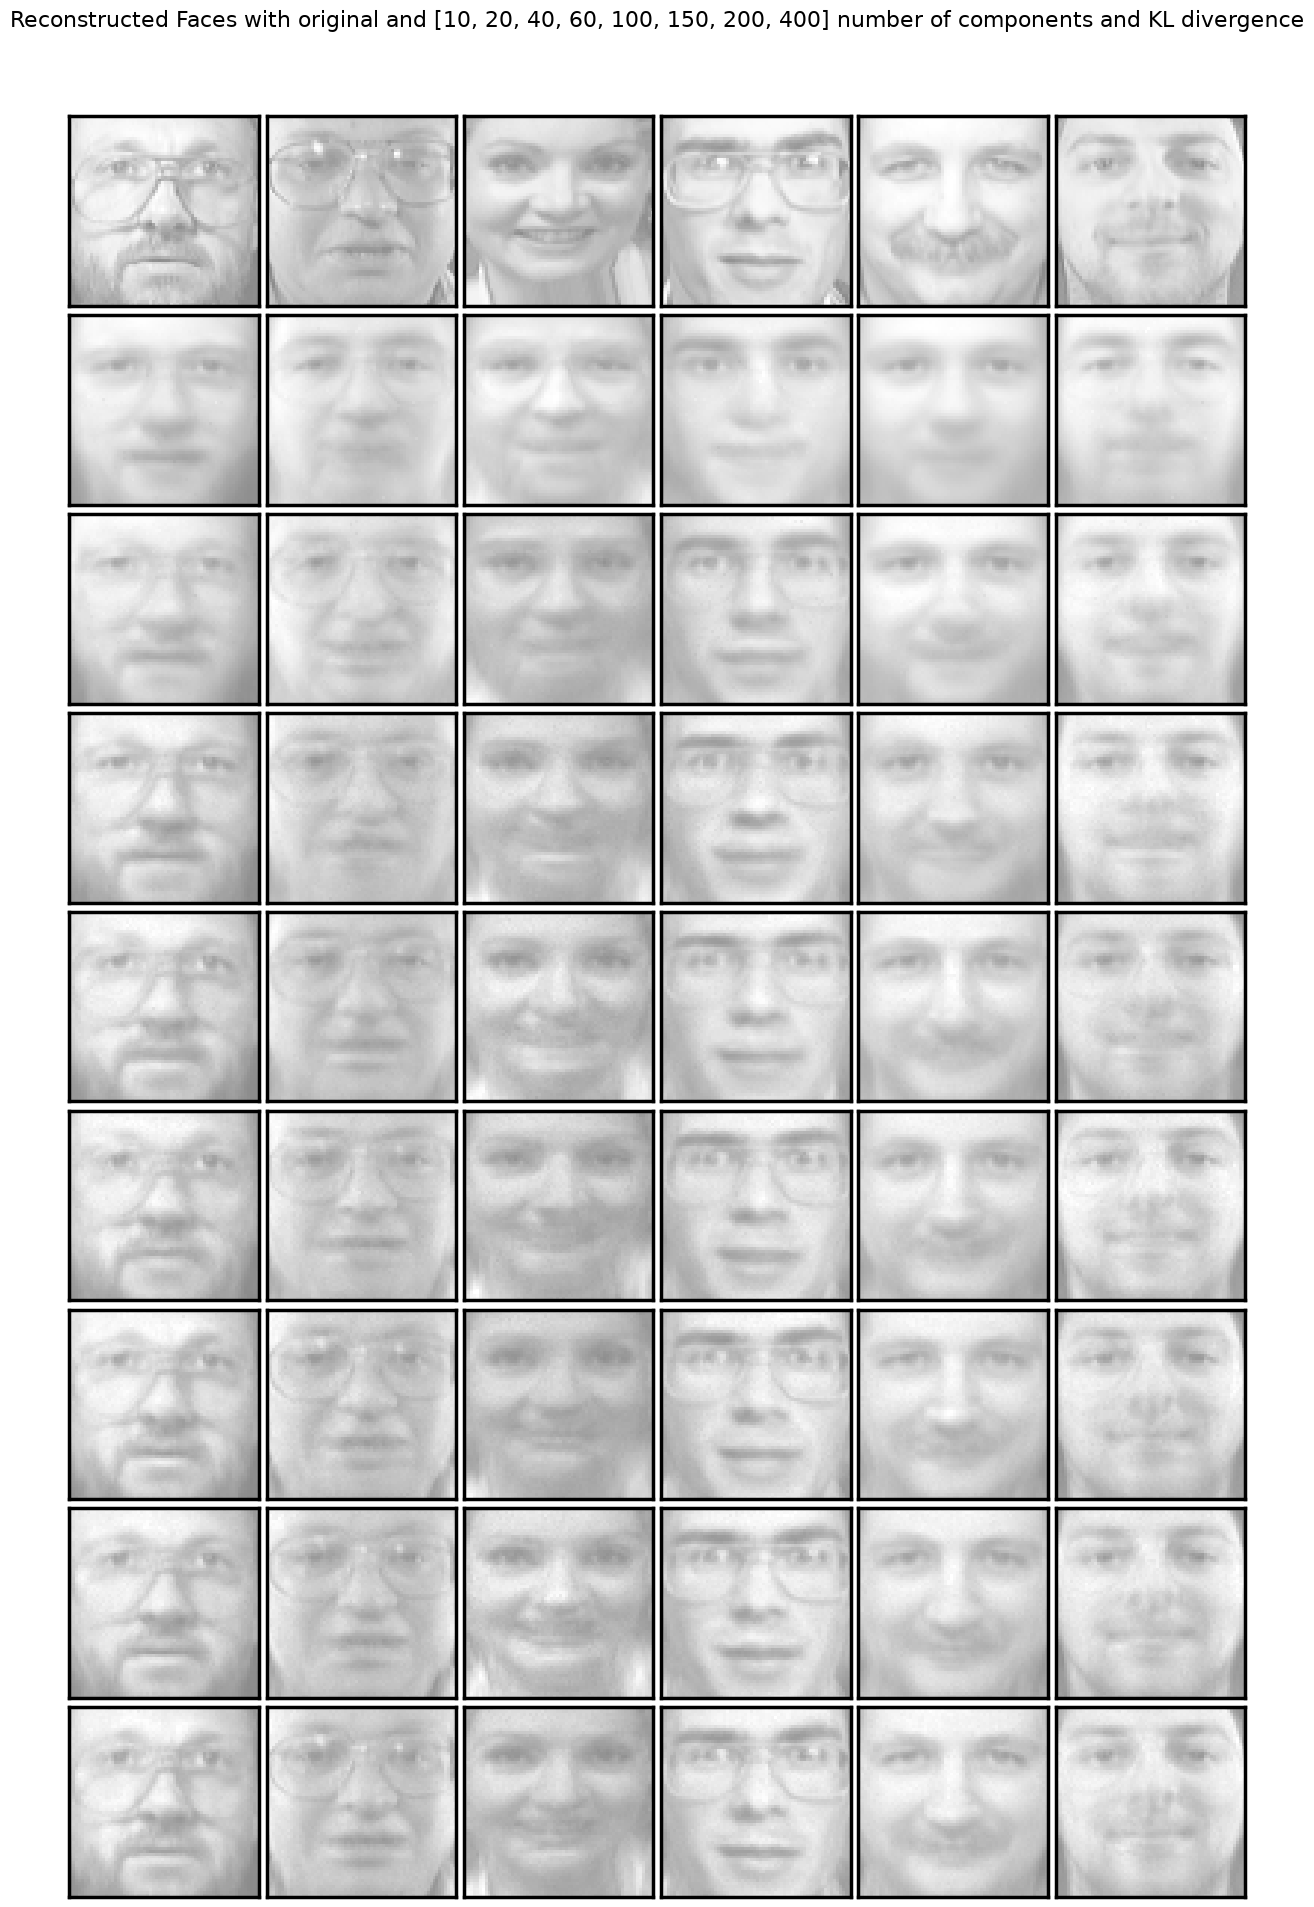

In [12]:
#TODO : plot reconstructed faces for different number of components with KL divergence

number_of_components = [10, 20, 40, 60, 100, 150, 200, 400]
reconstructed_images_sample = list(faces[:6])


for num in number_of_components: 
    mynmf = MYNMF(n_components=num, loss = "KL")
    mynmf.fit_transform(data = faces.T)
    
    reconstruction = (mynmf.D_ @ mynmf.S_).T
    reconstructed_images_sample += list(reconstruction[:6])
    
plot_gallery(title=f"Reconstructed Faces with original and {number_of_components} number of components and KL divergence", 
            images=reconstructed_images_sample, 
            image_shape=image_shape,nrow=9,ncol=6)


**Comments:** Same as before, the reconstruction is quite satisfying. 

#### Comparison of the elements of the dictionary between the two distances

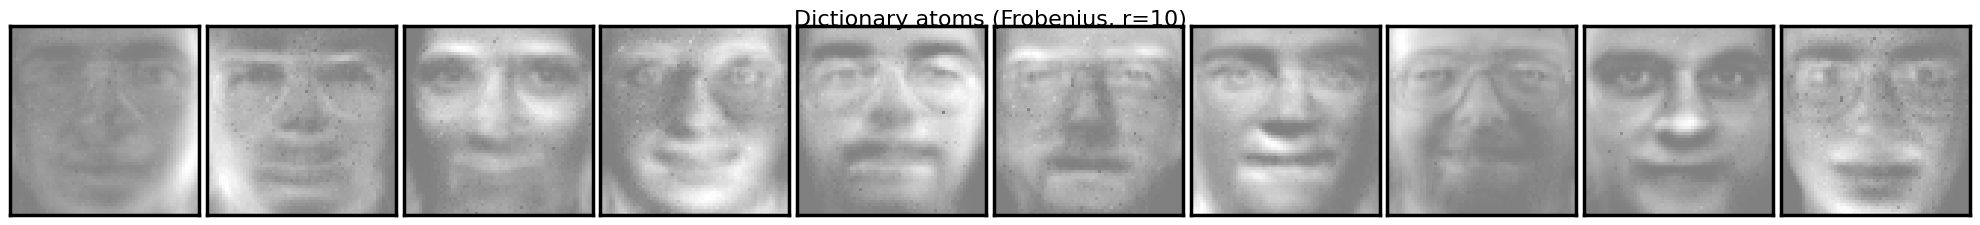

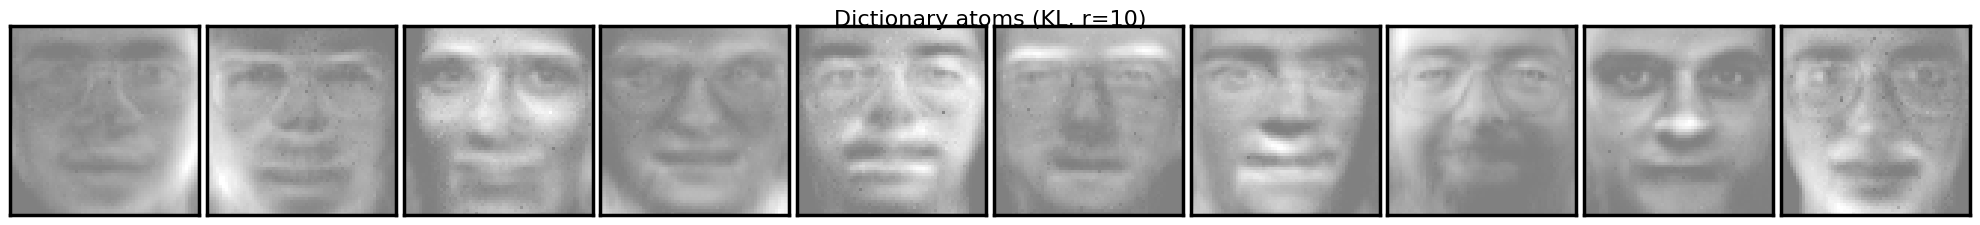

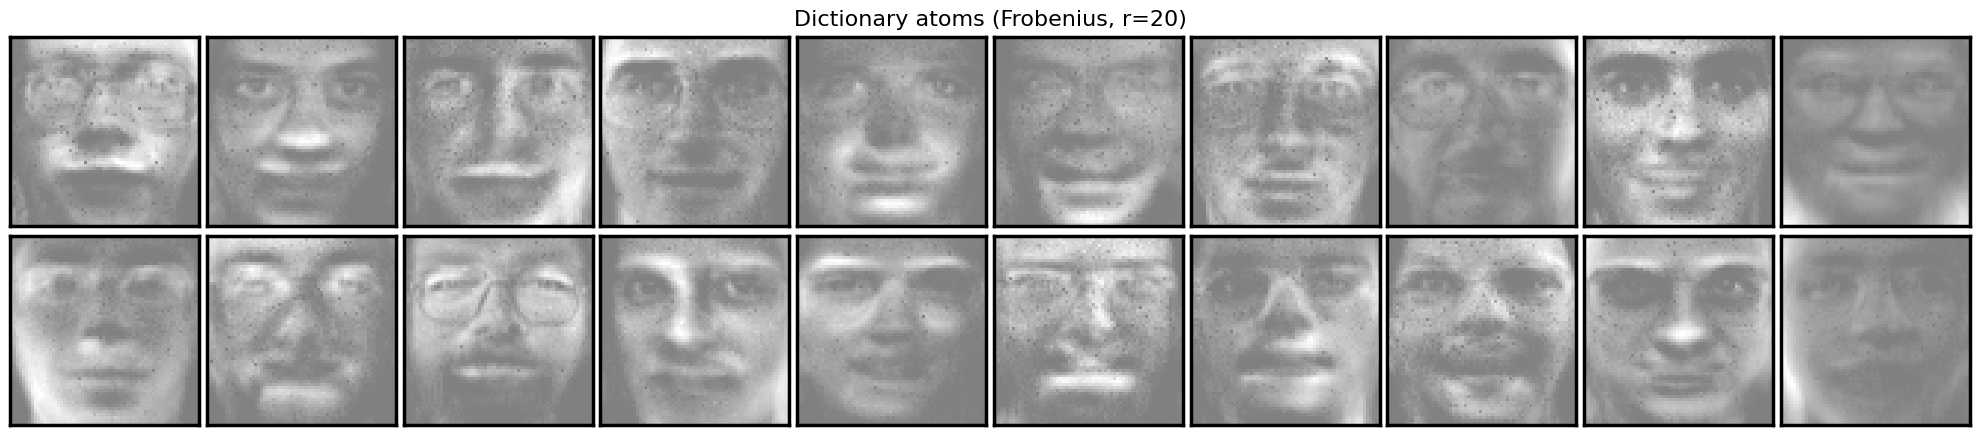

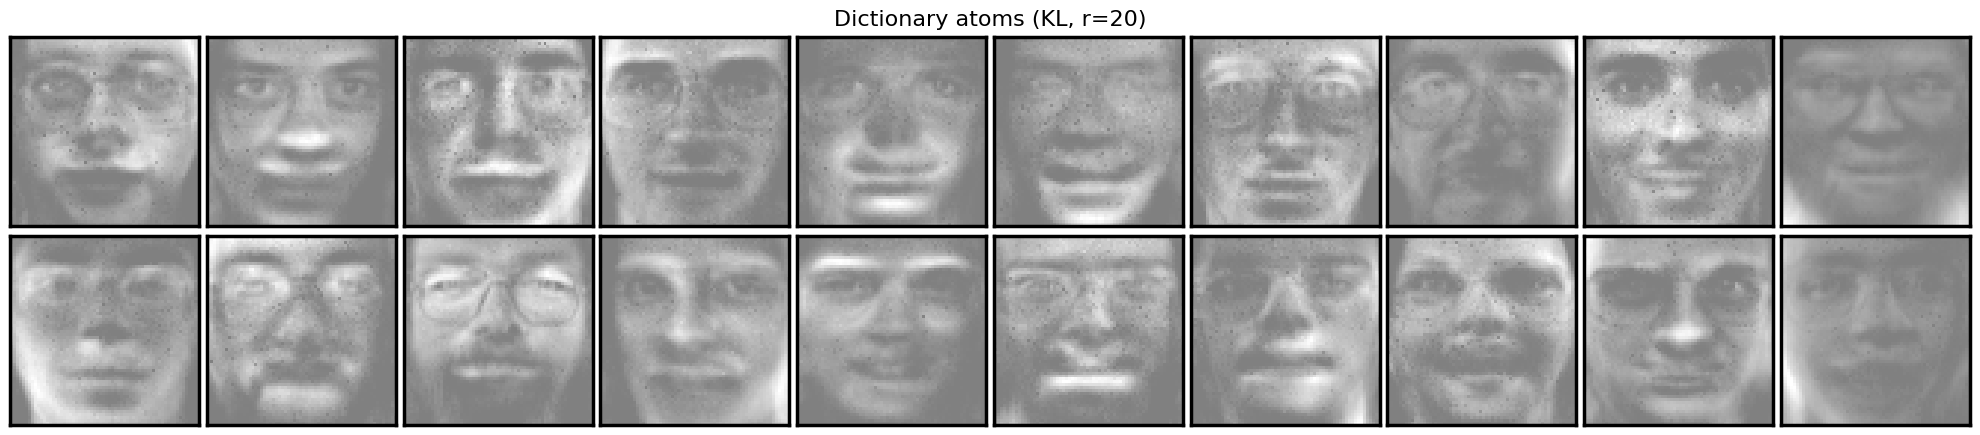

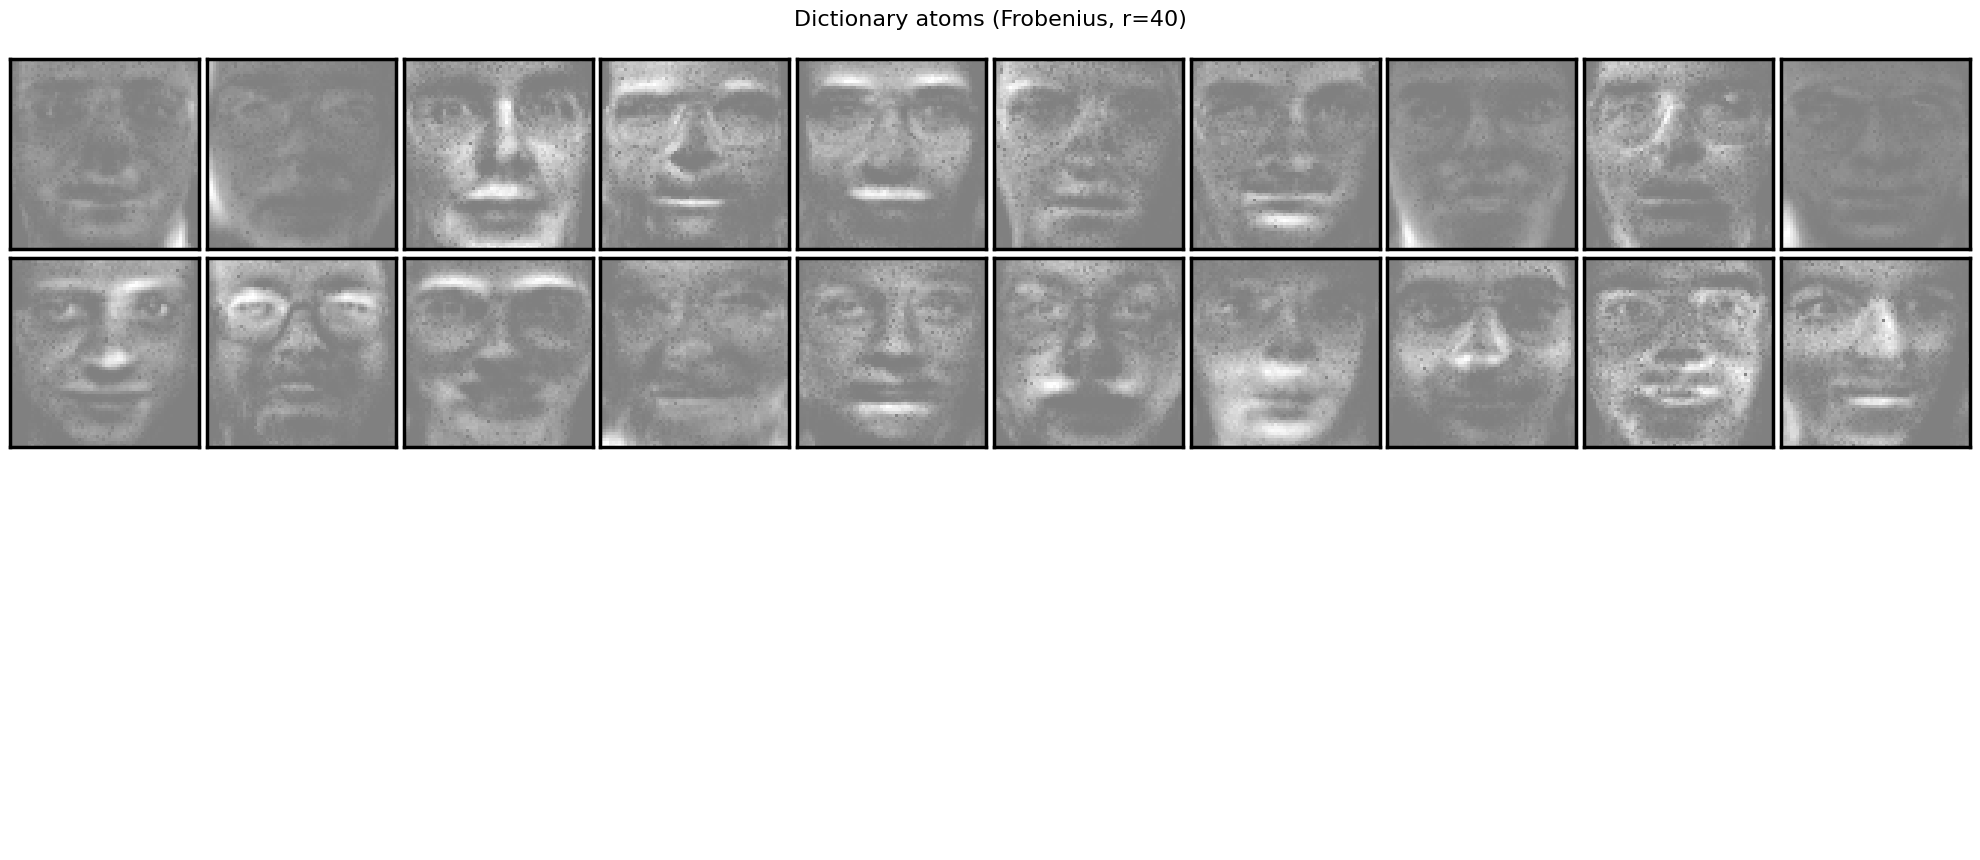

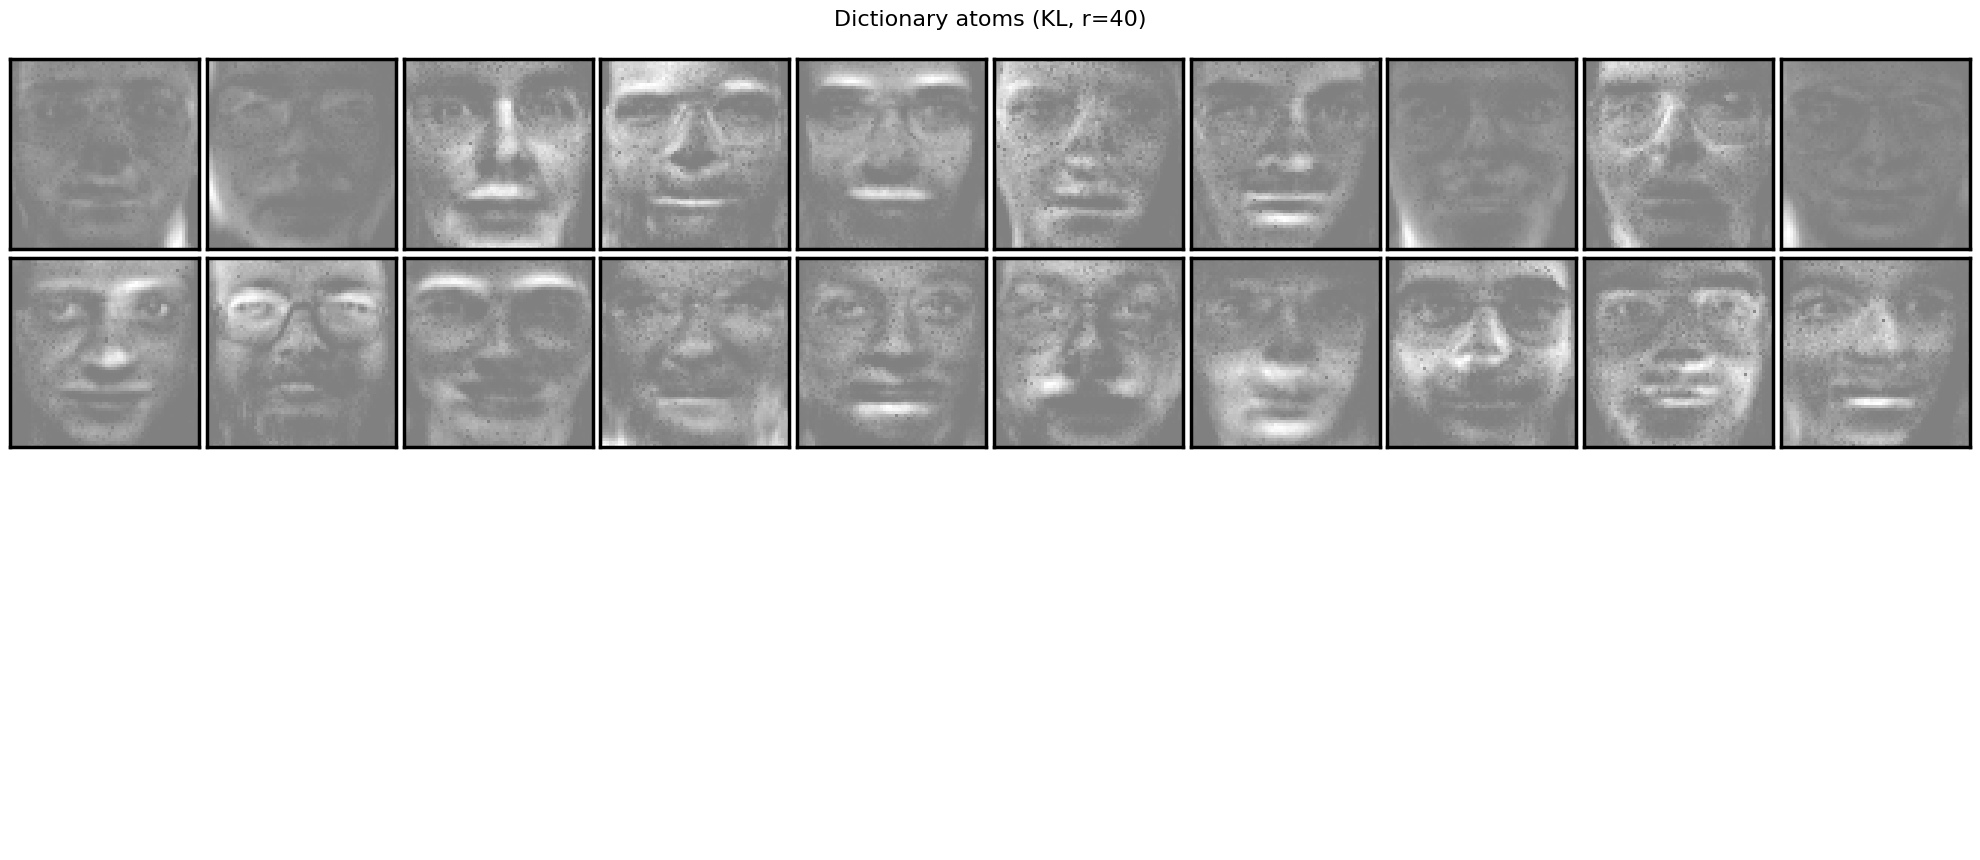

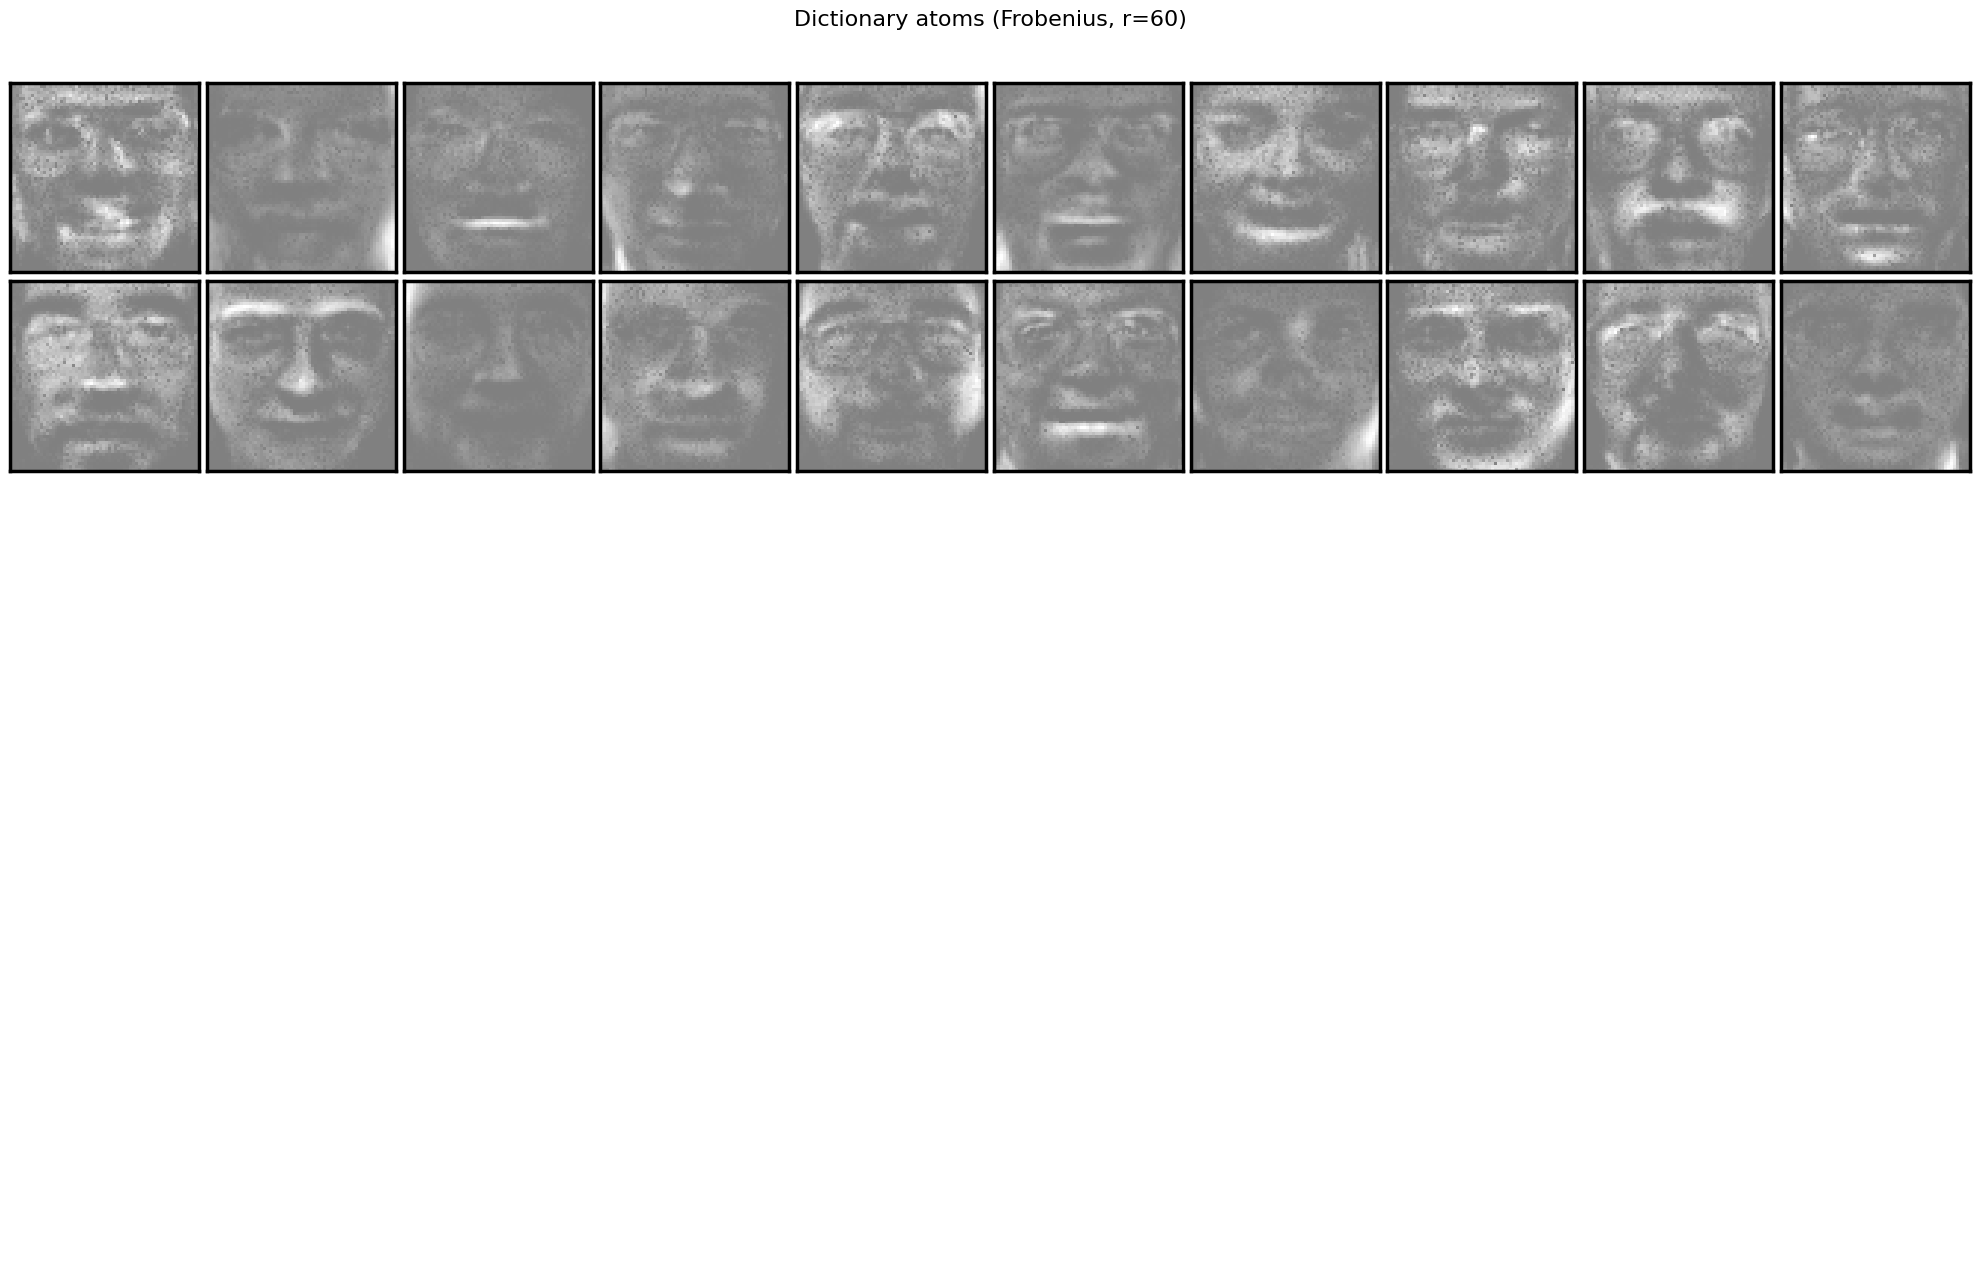

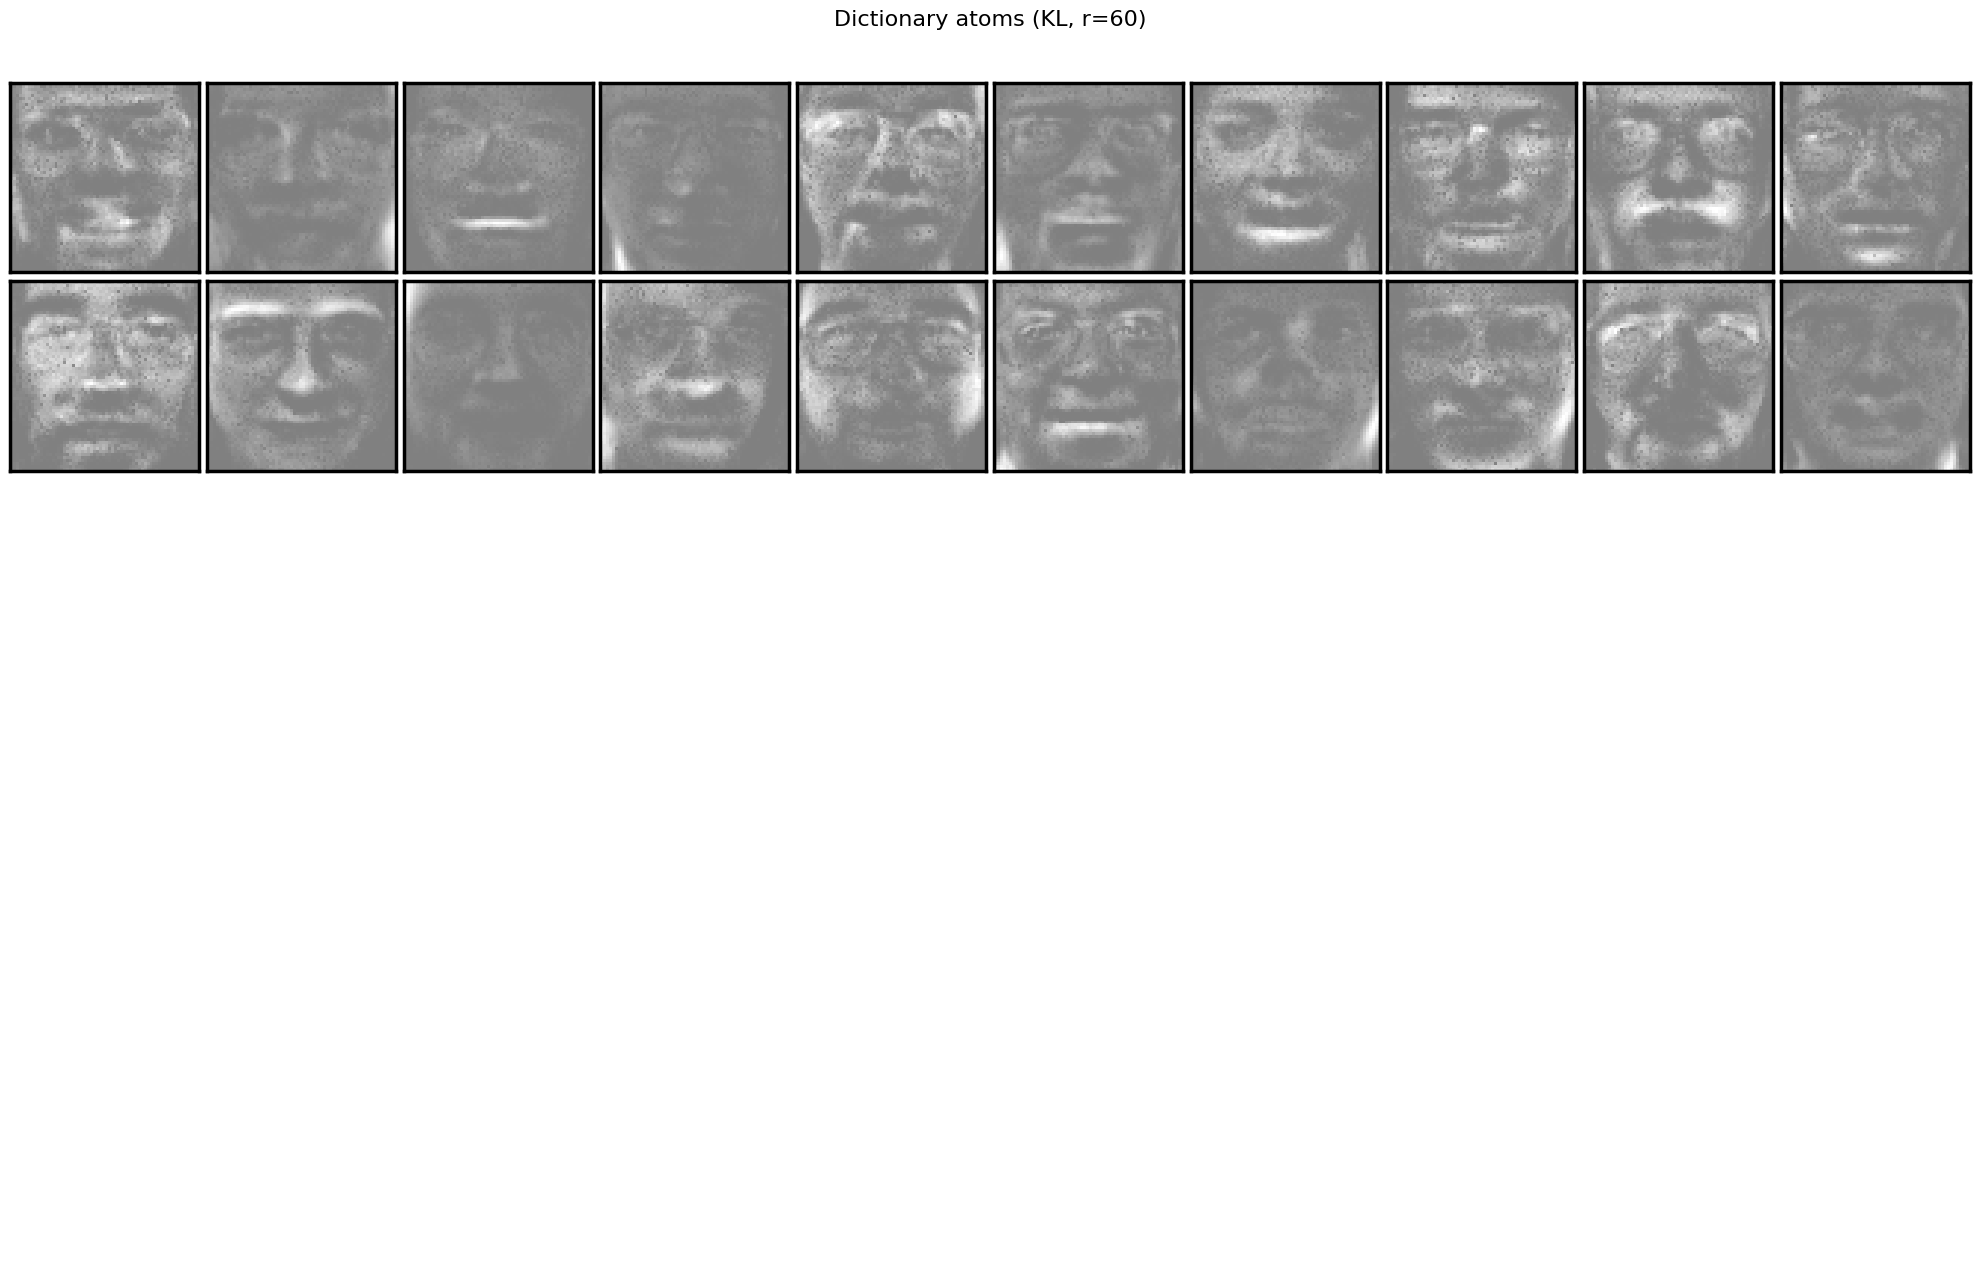

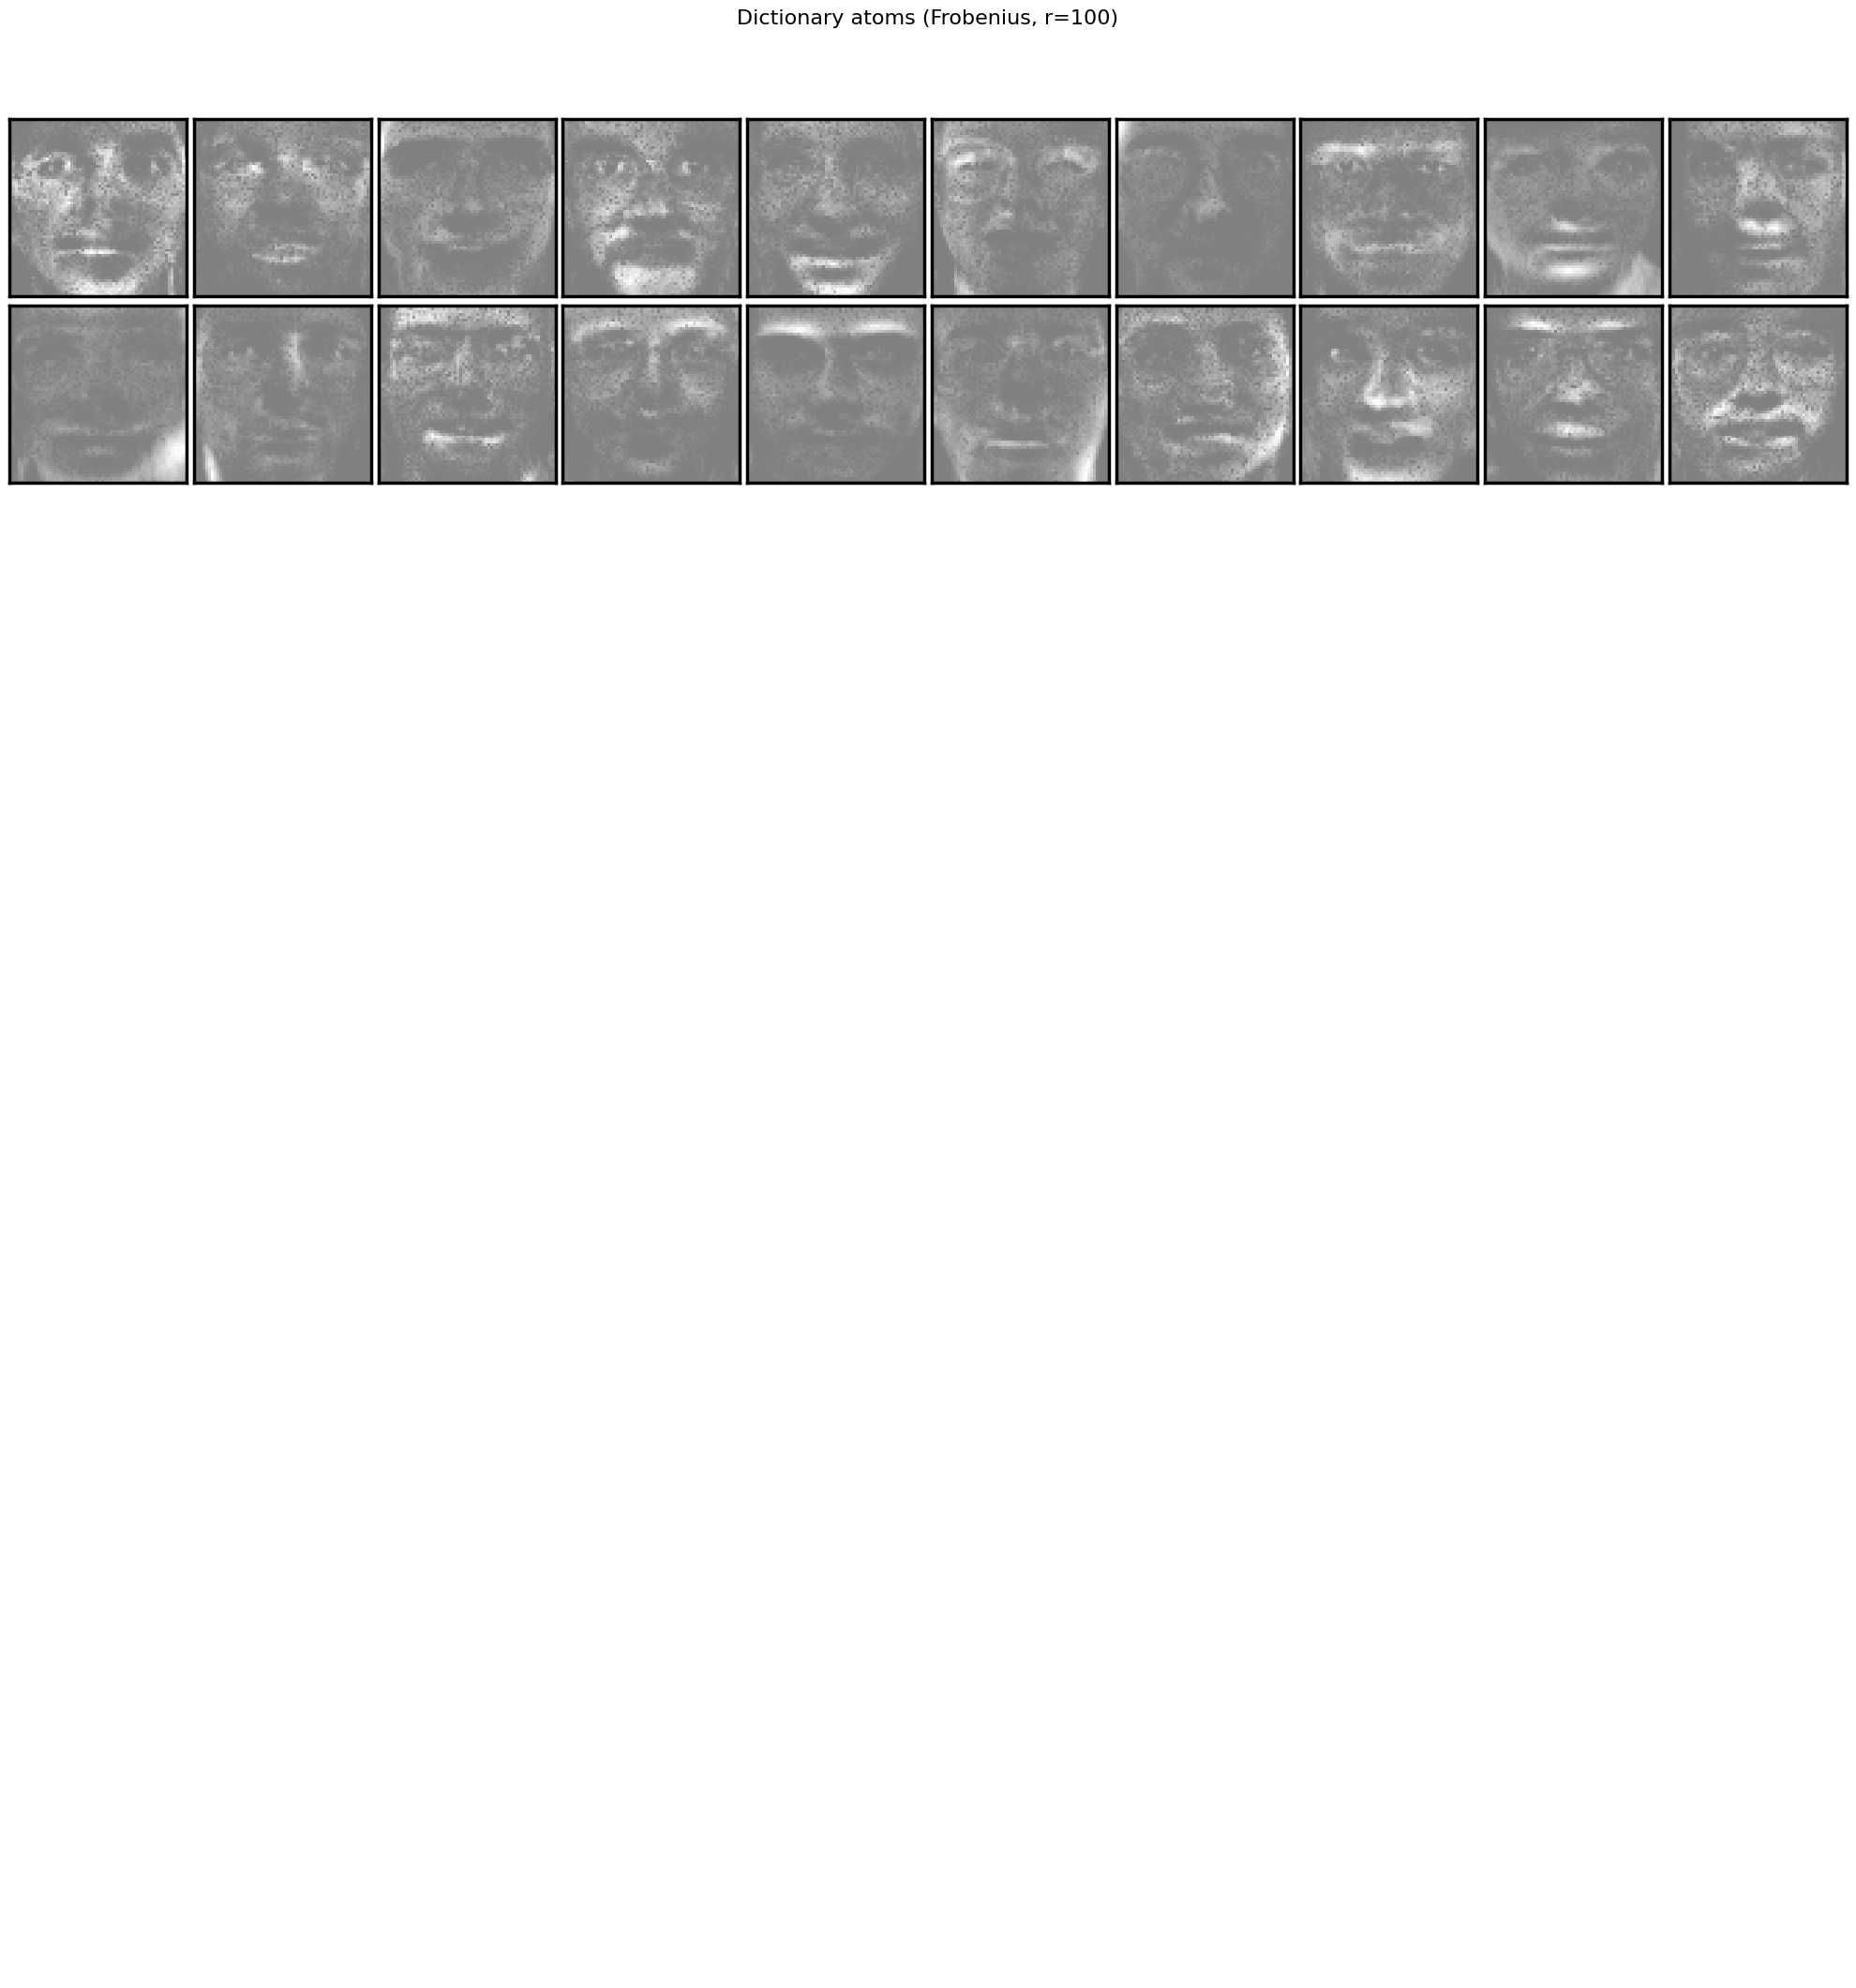

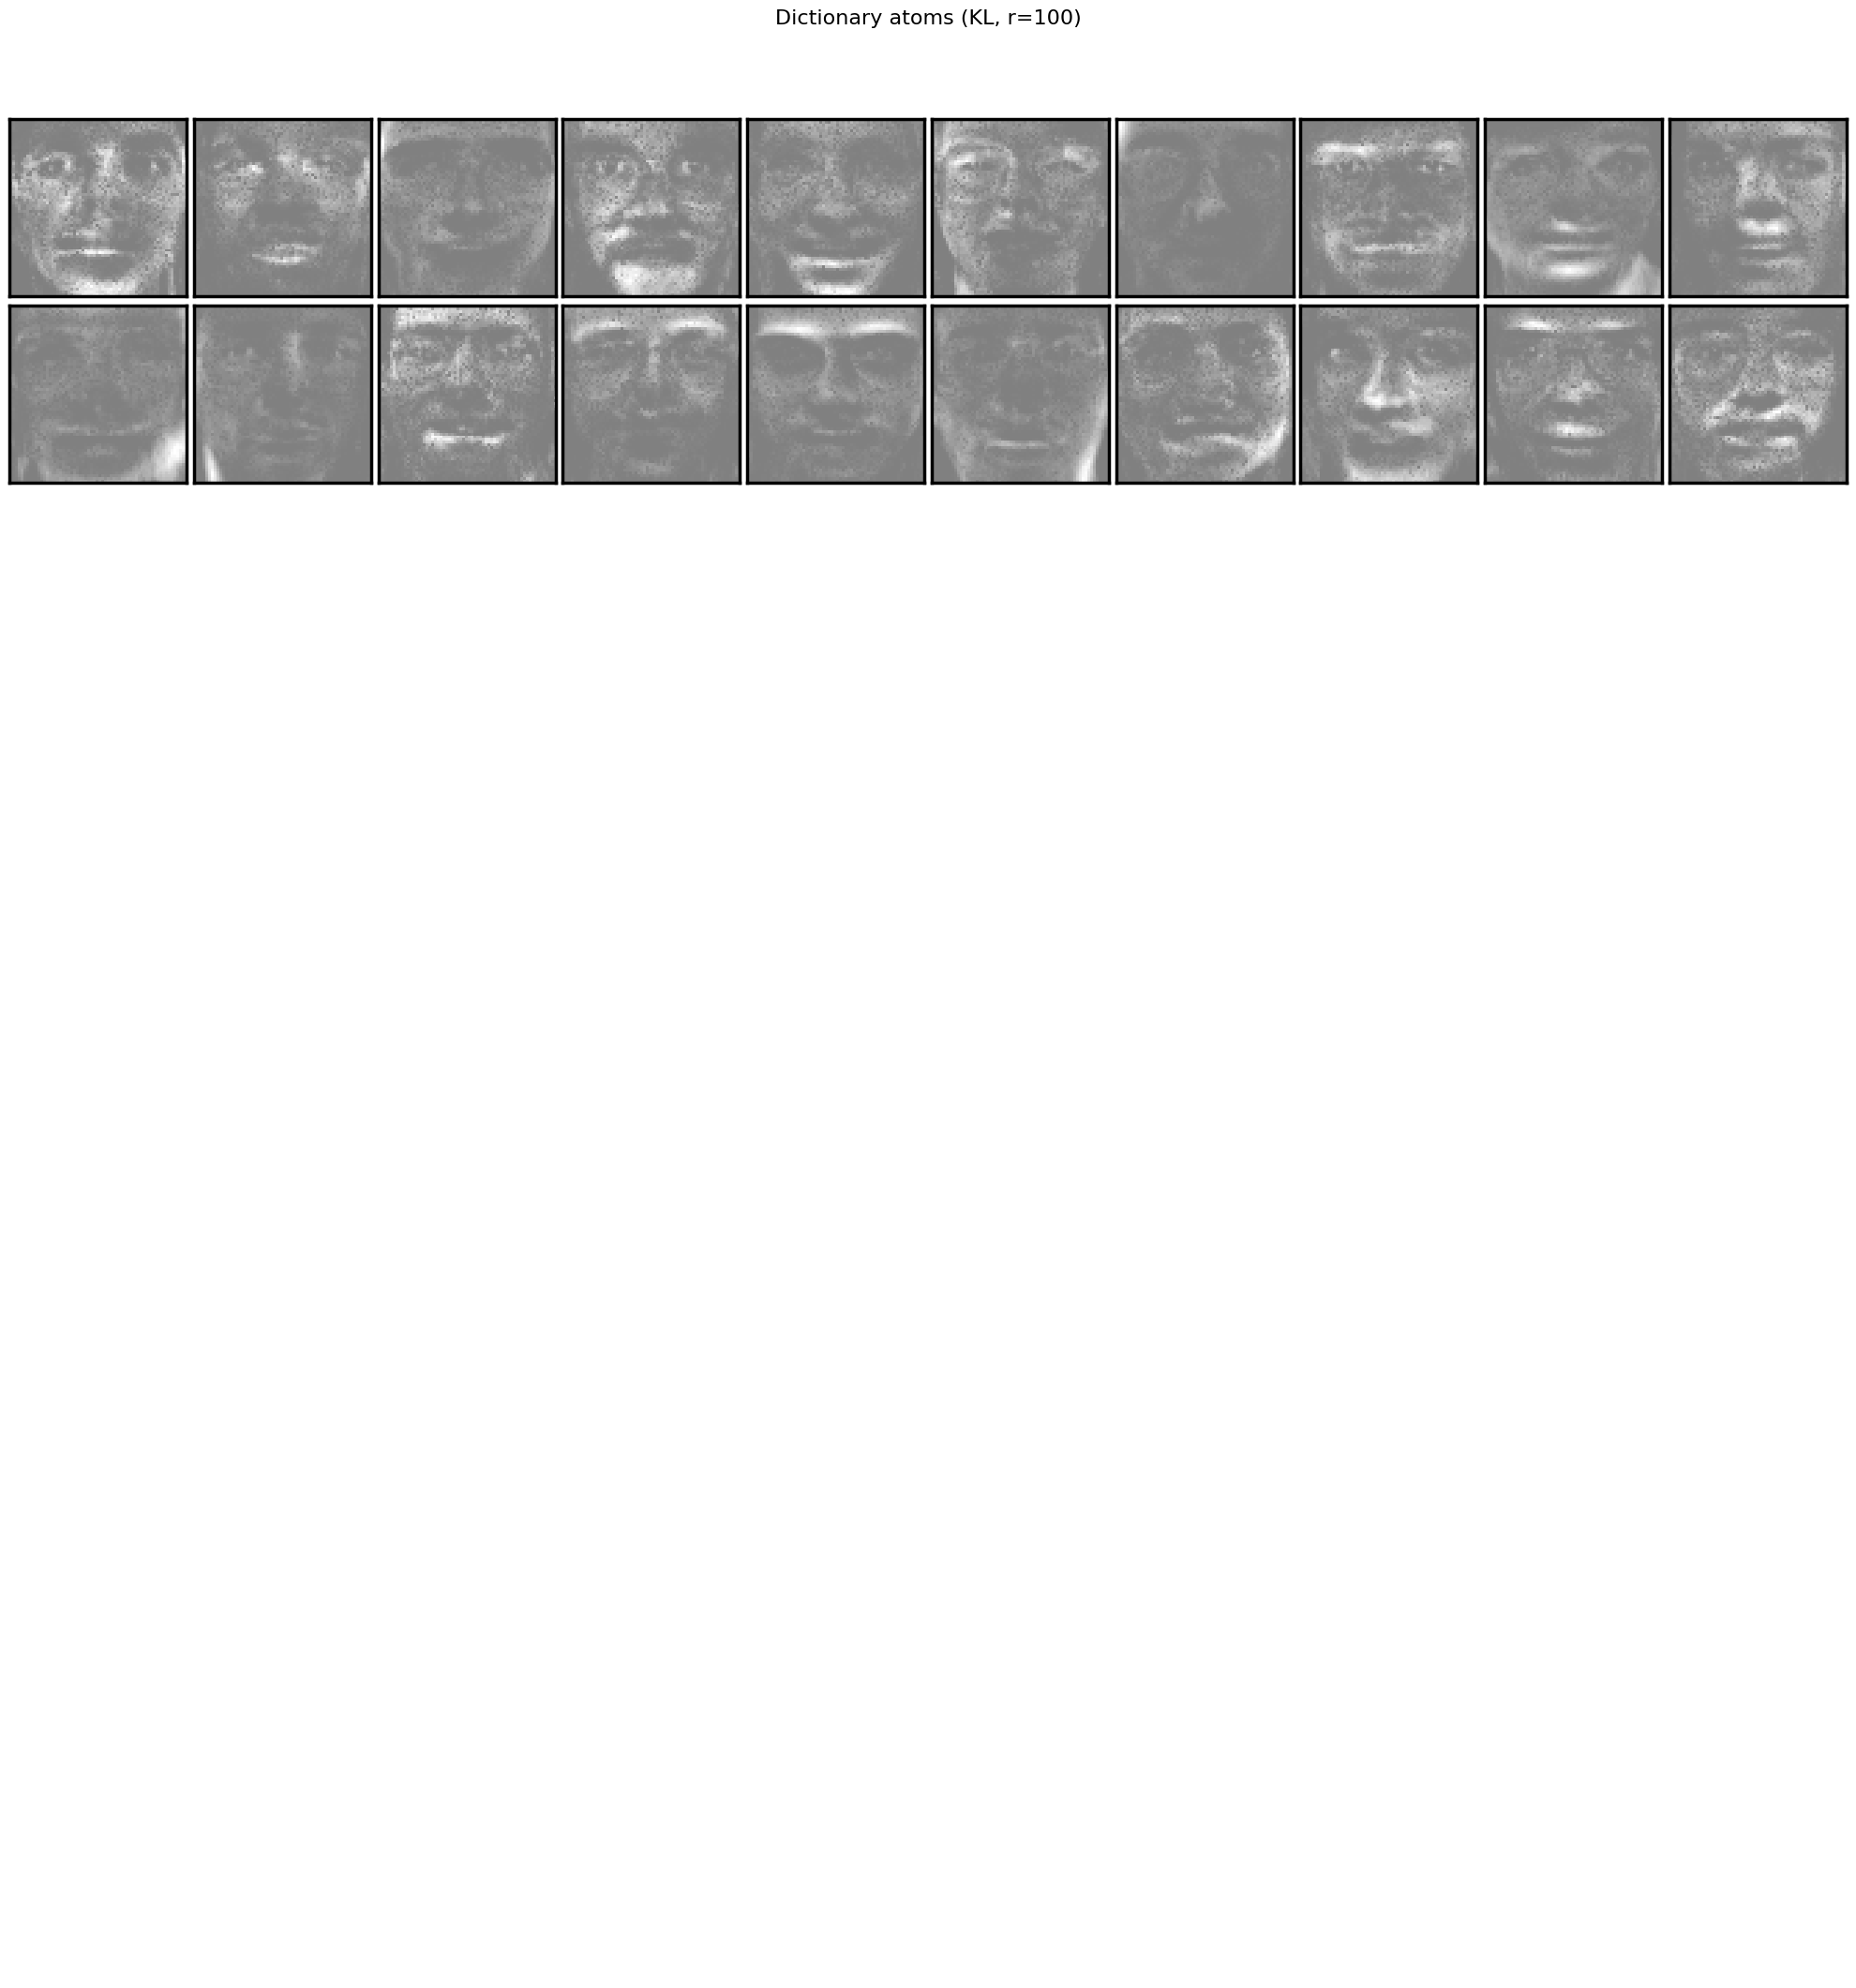

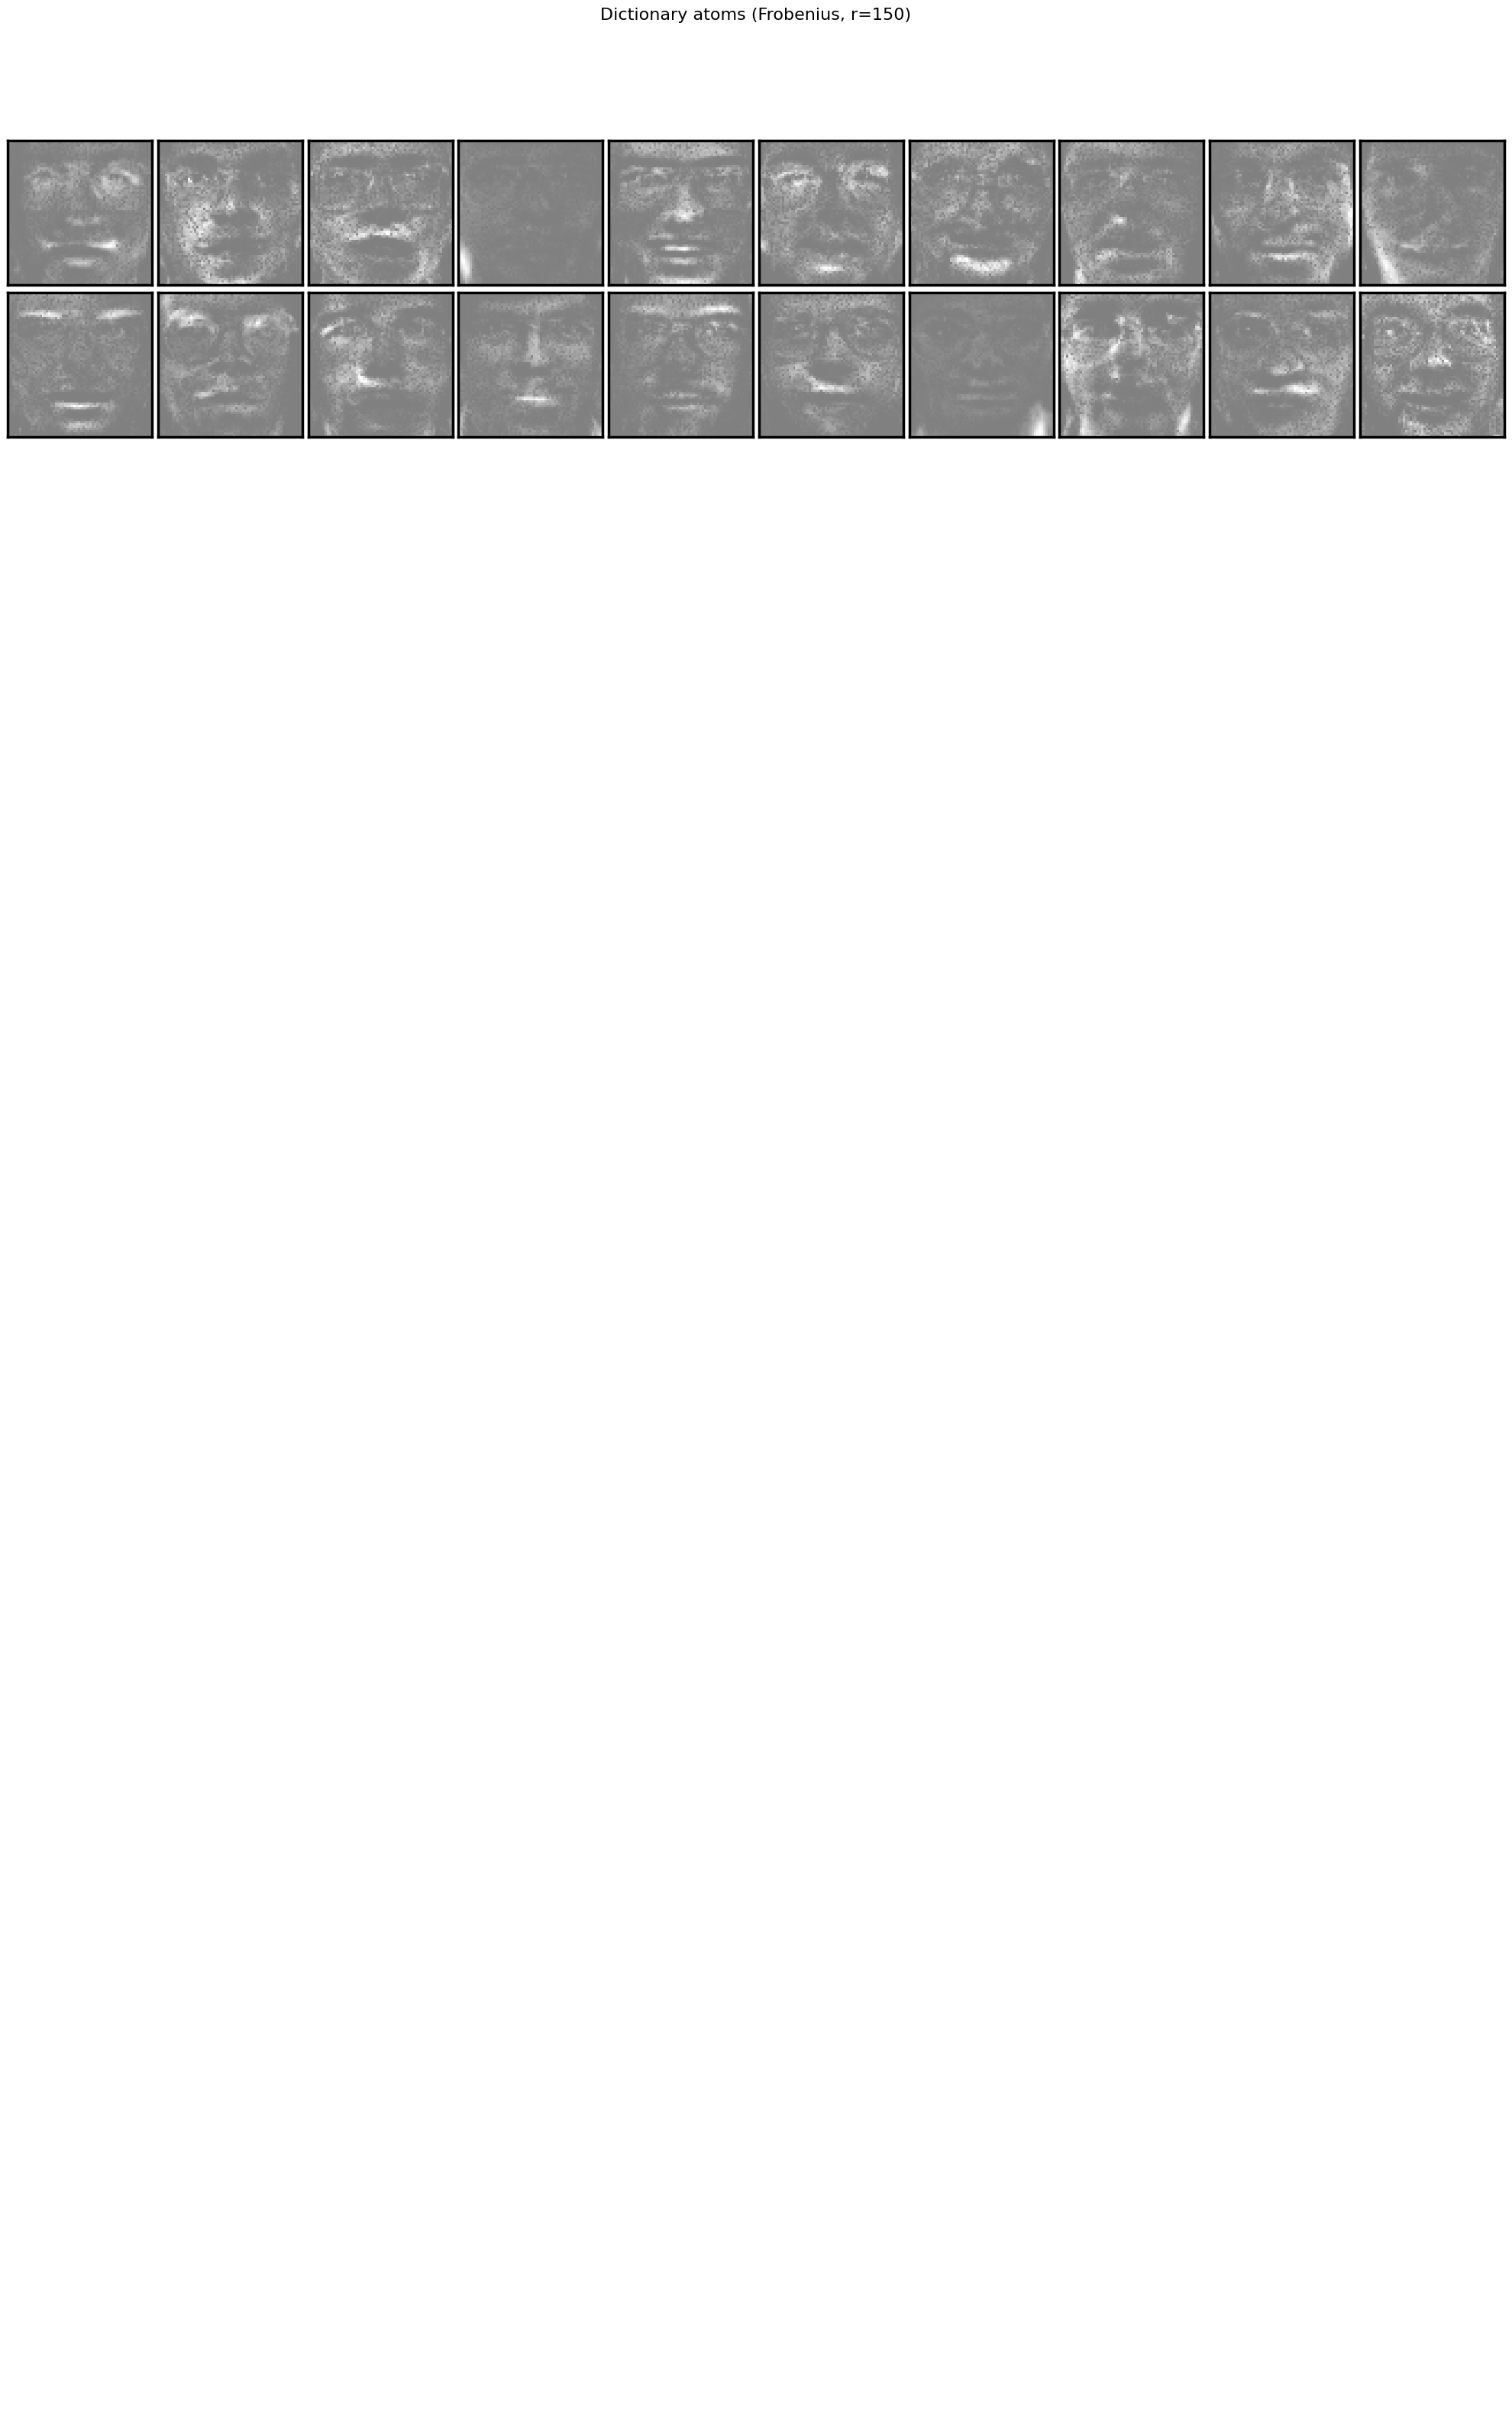

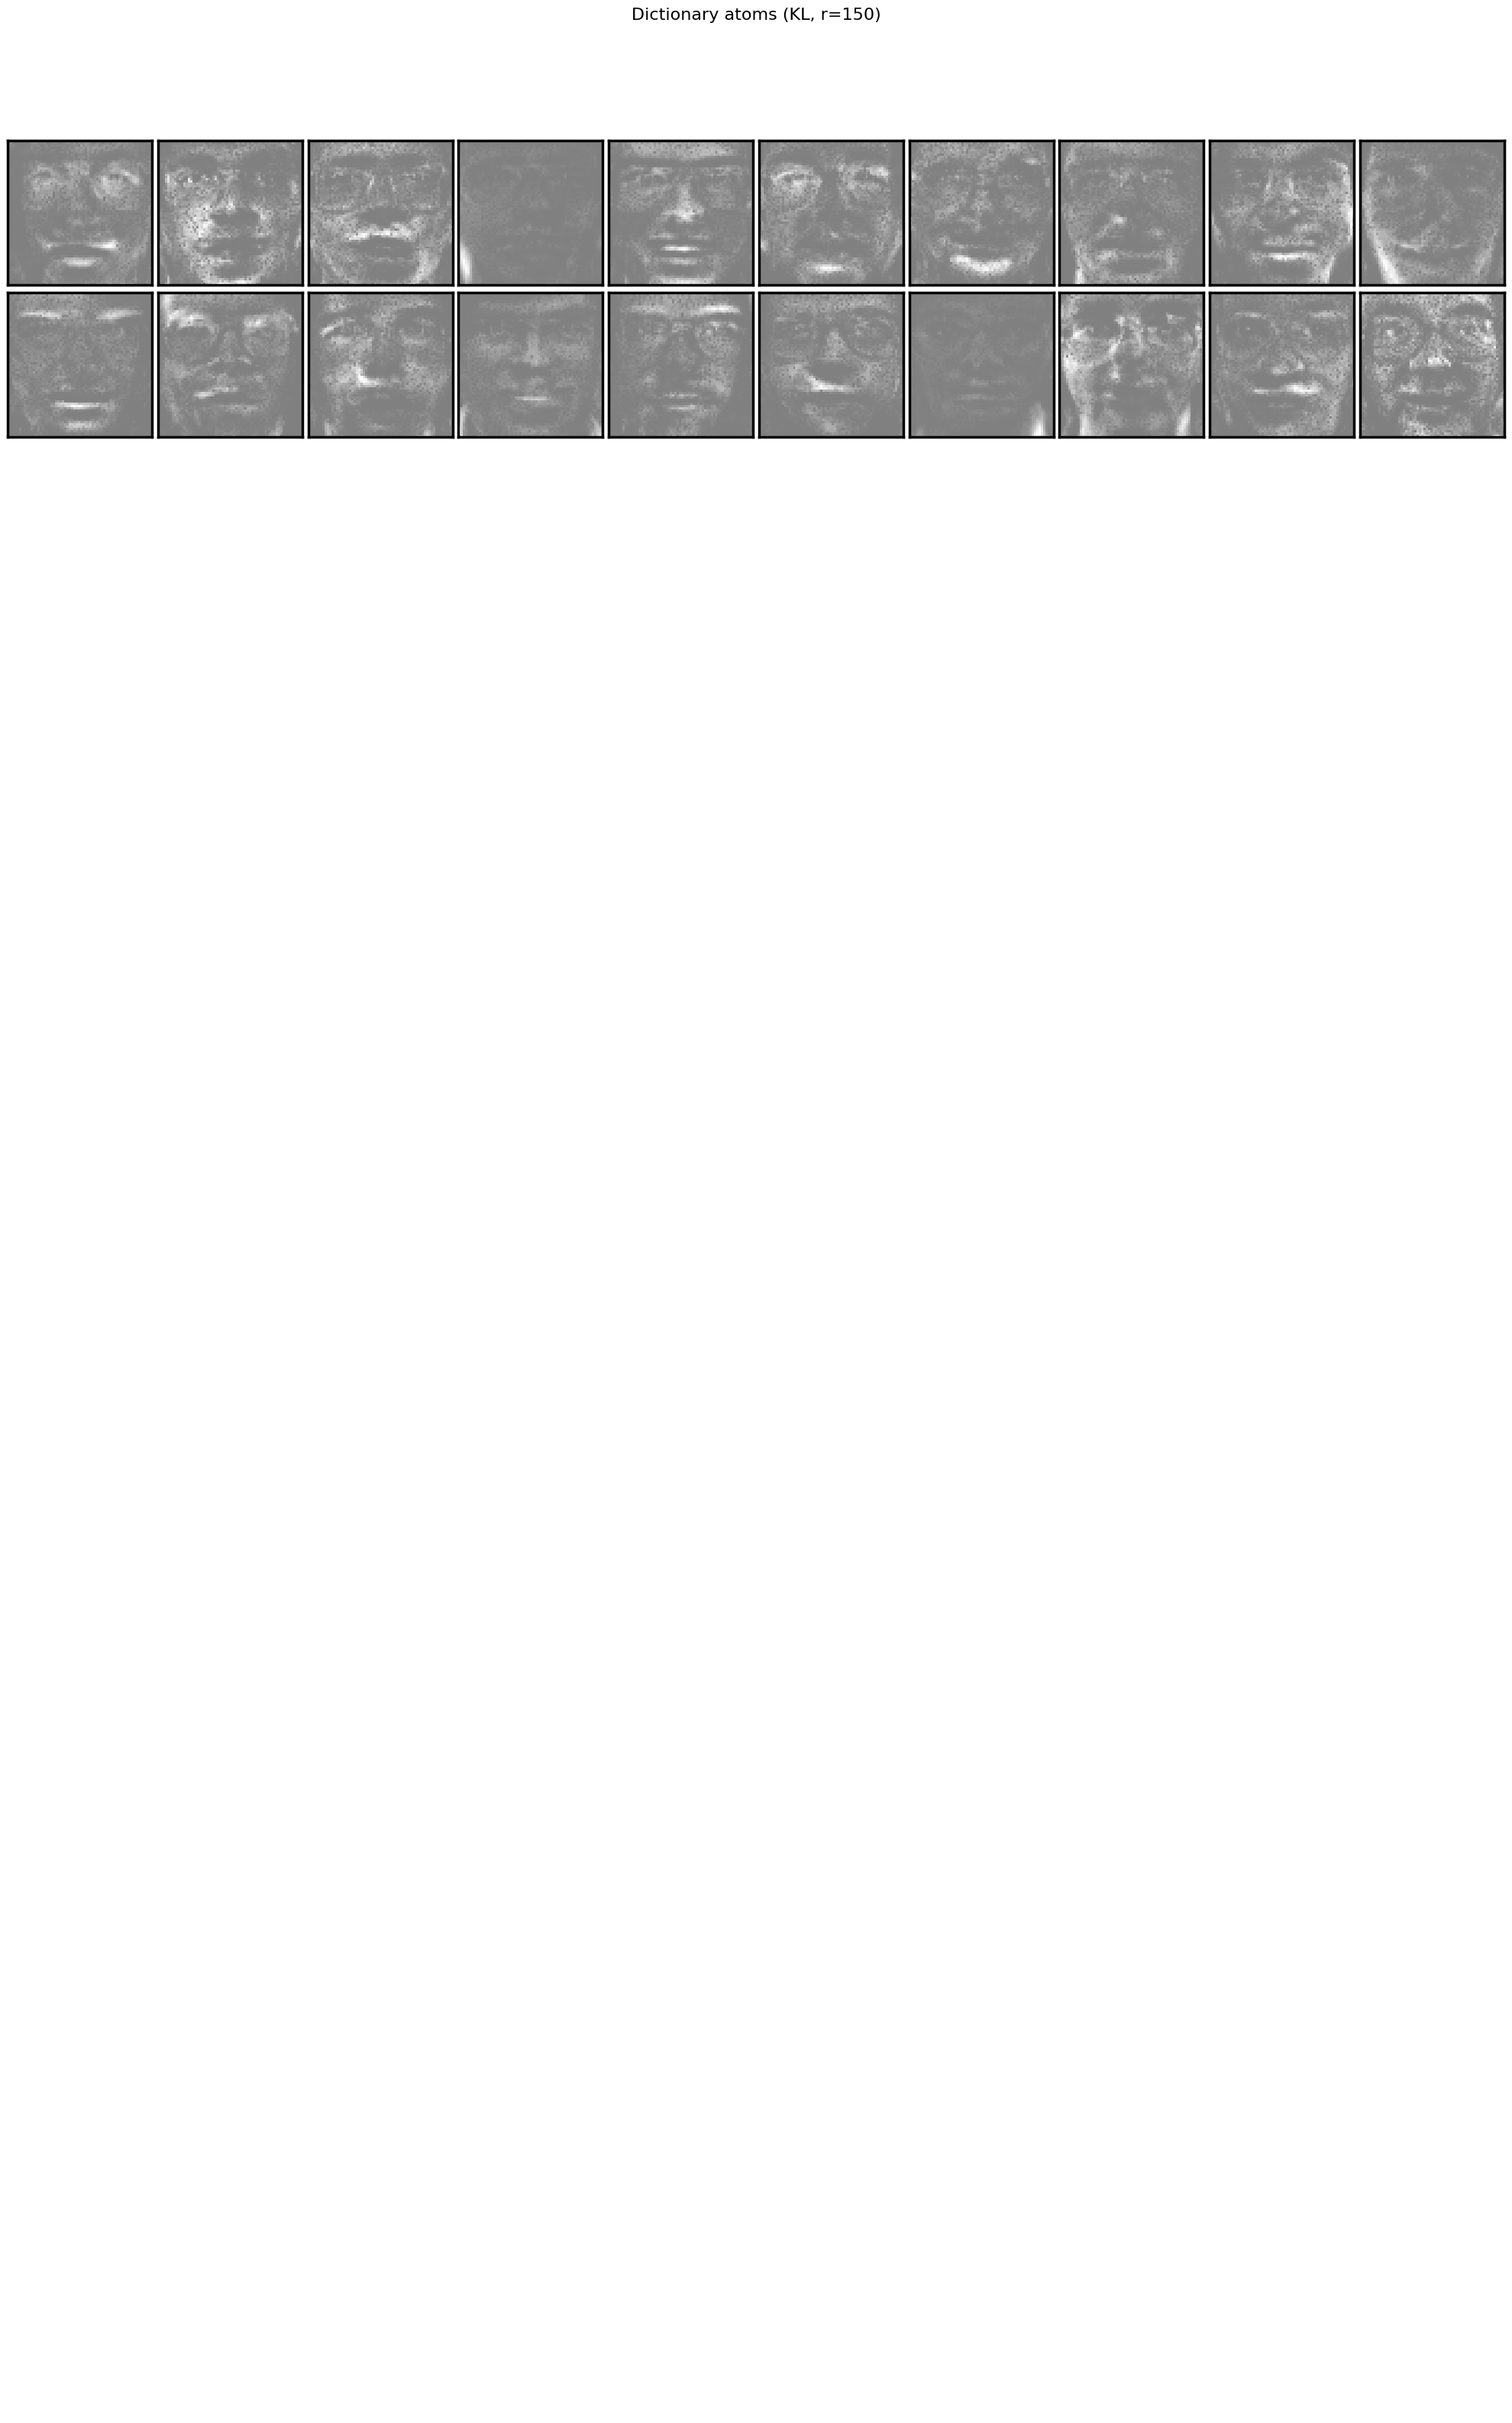

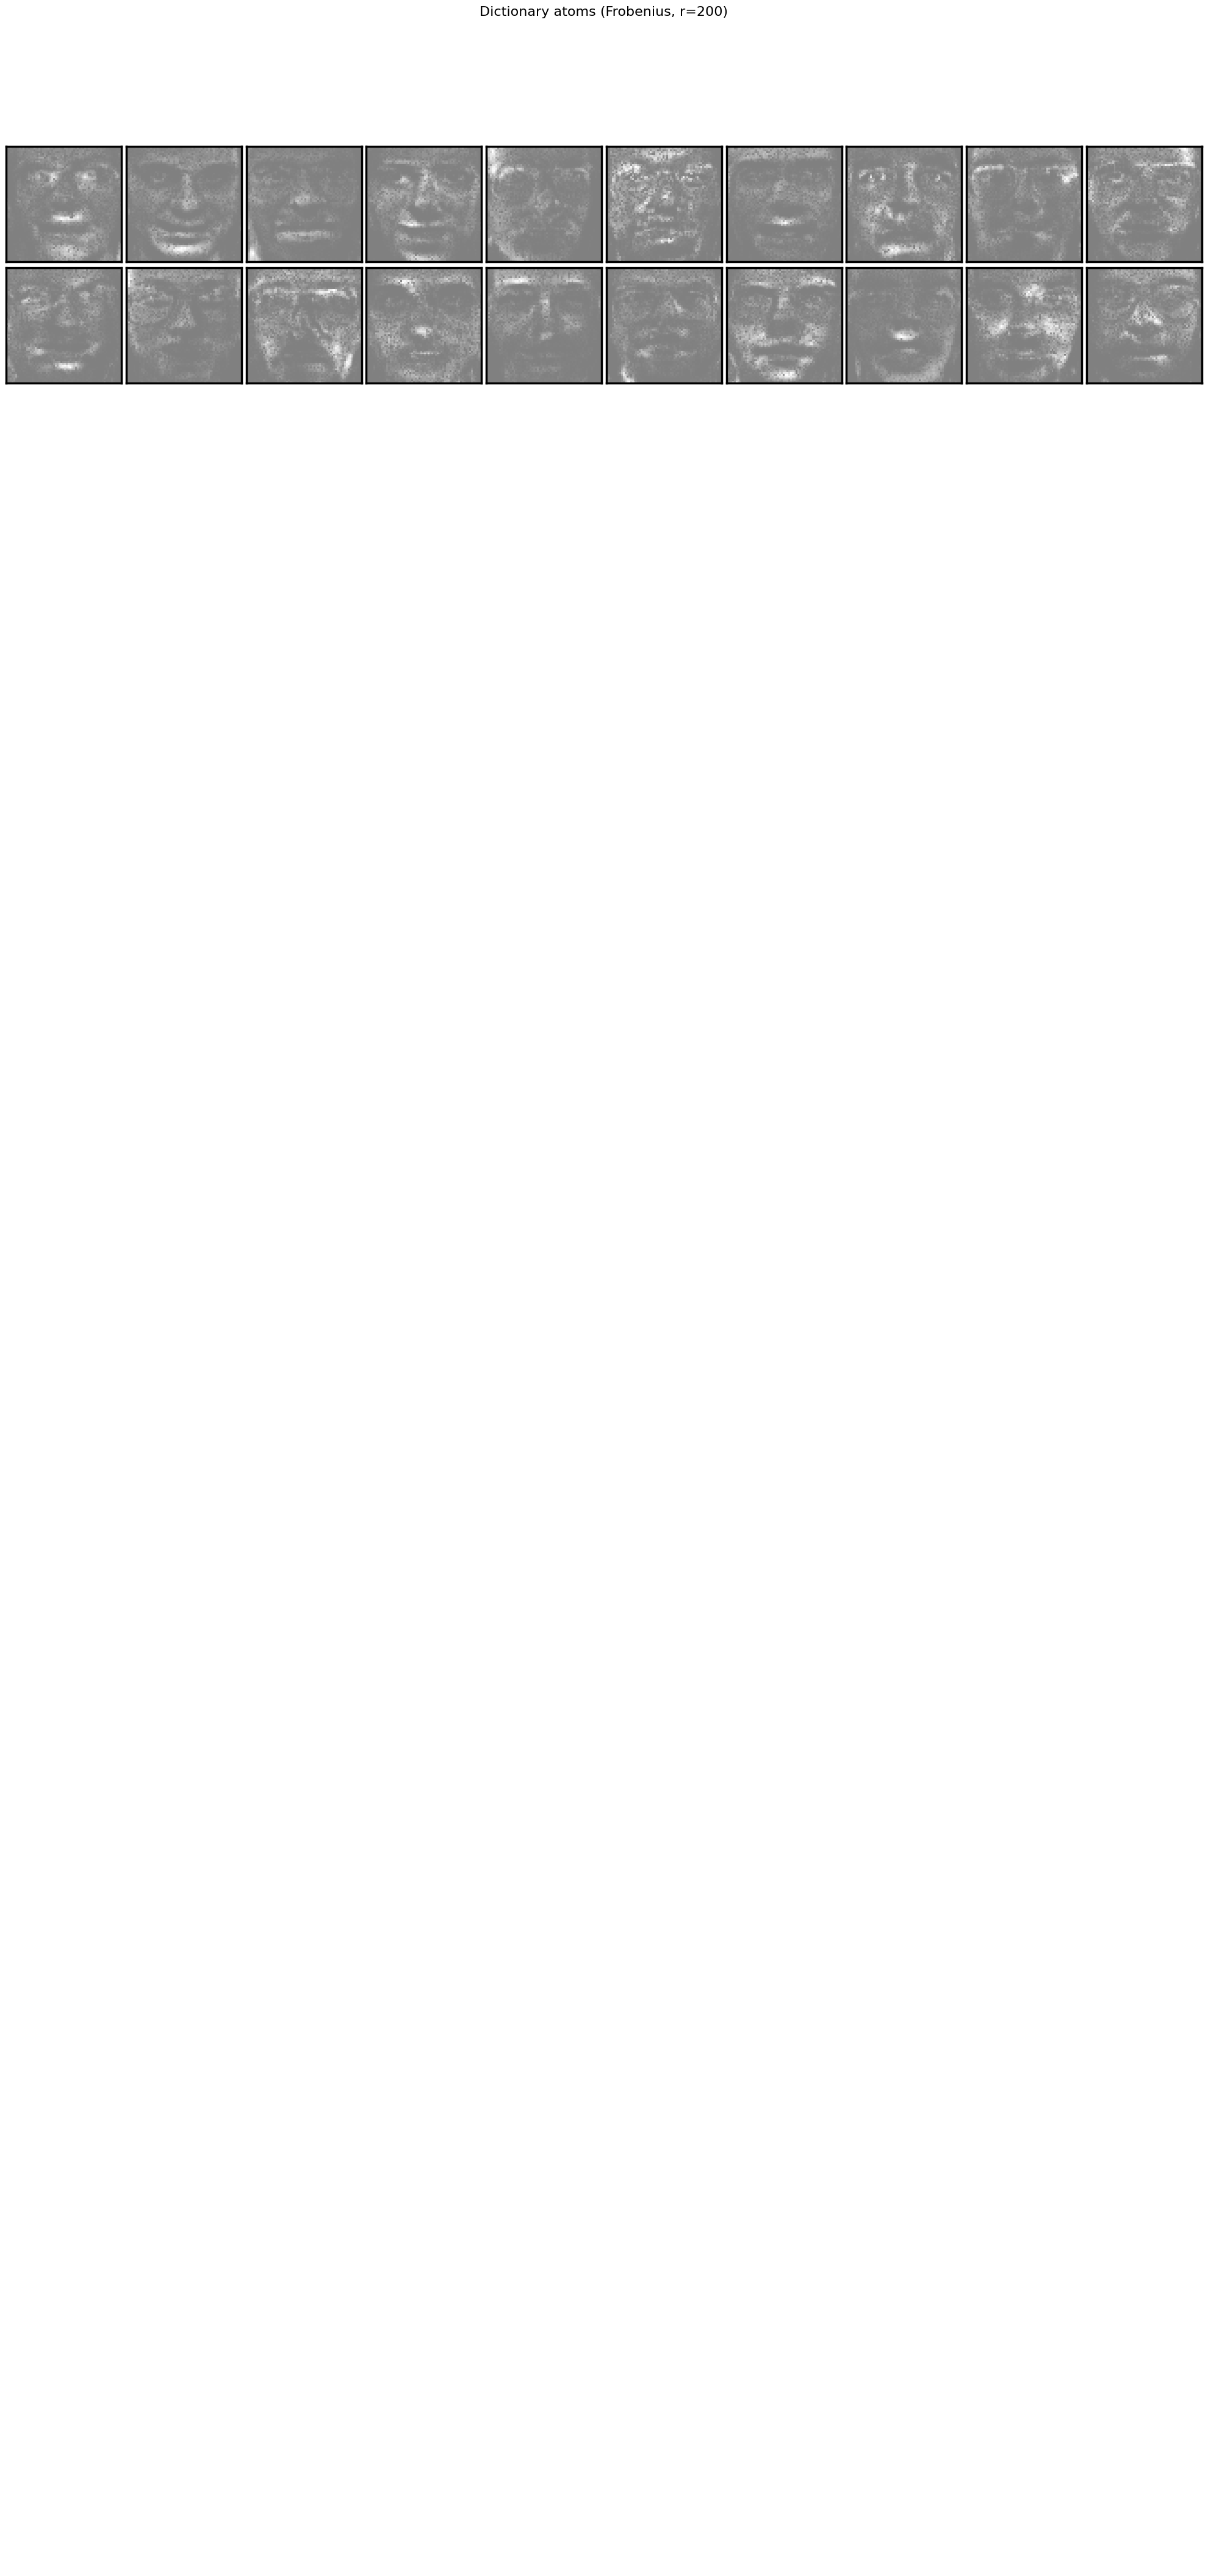

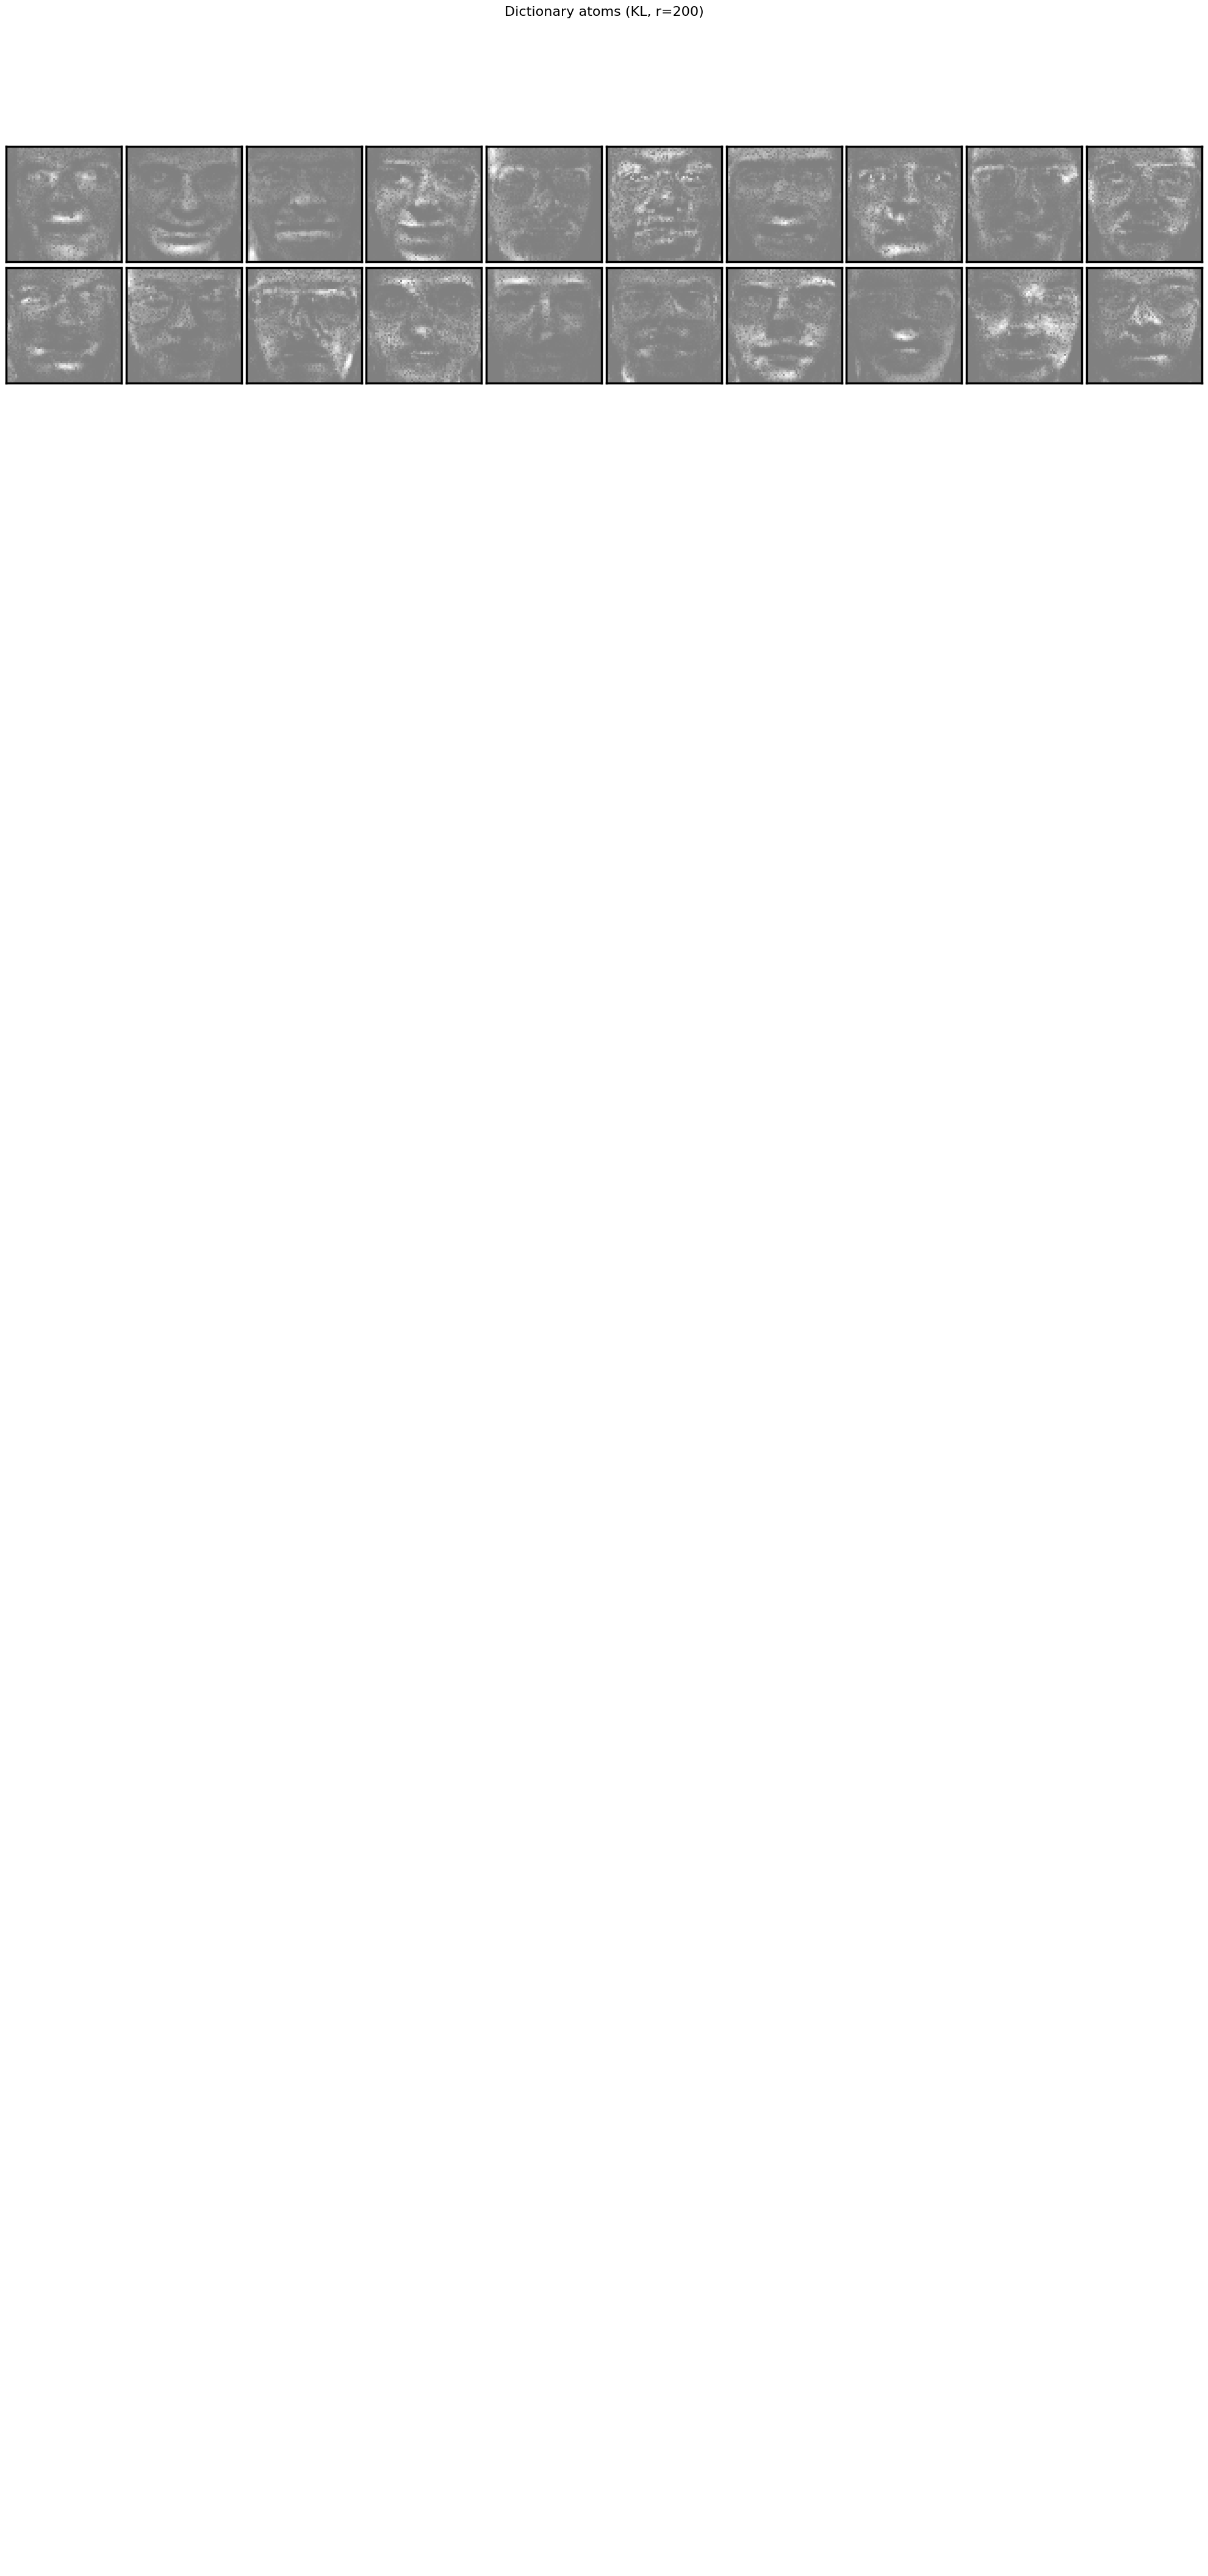

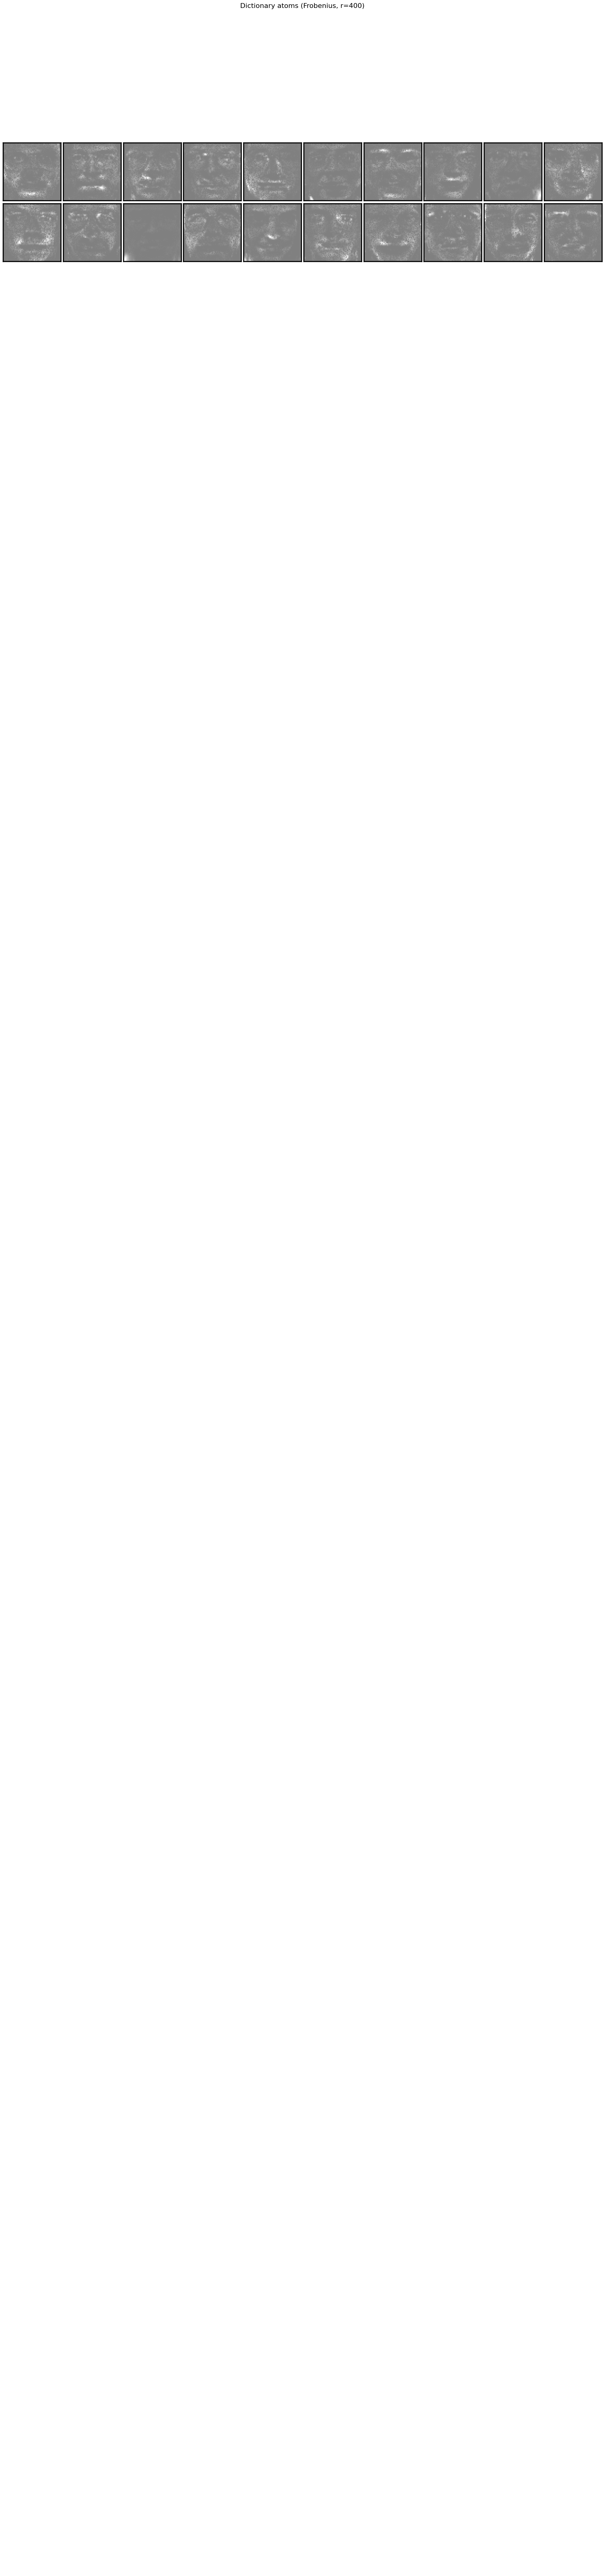

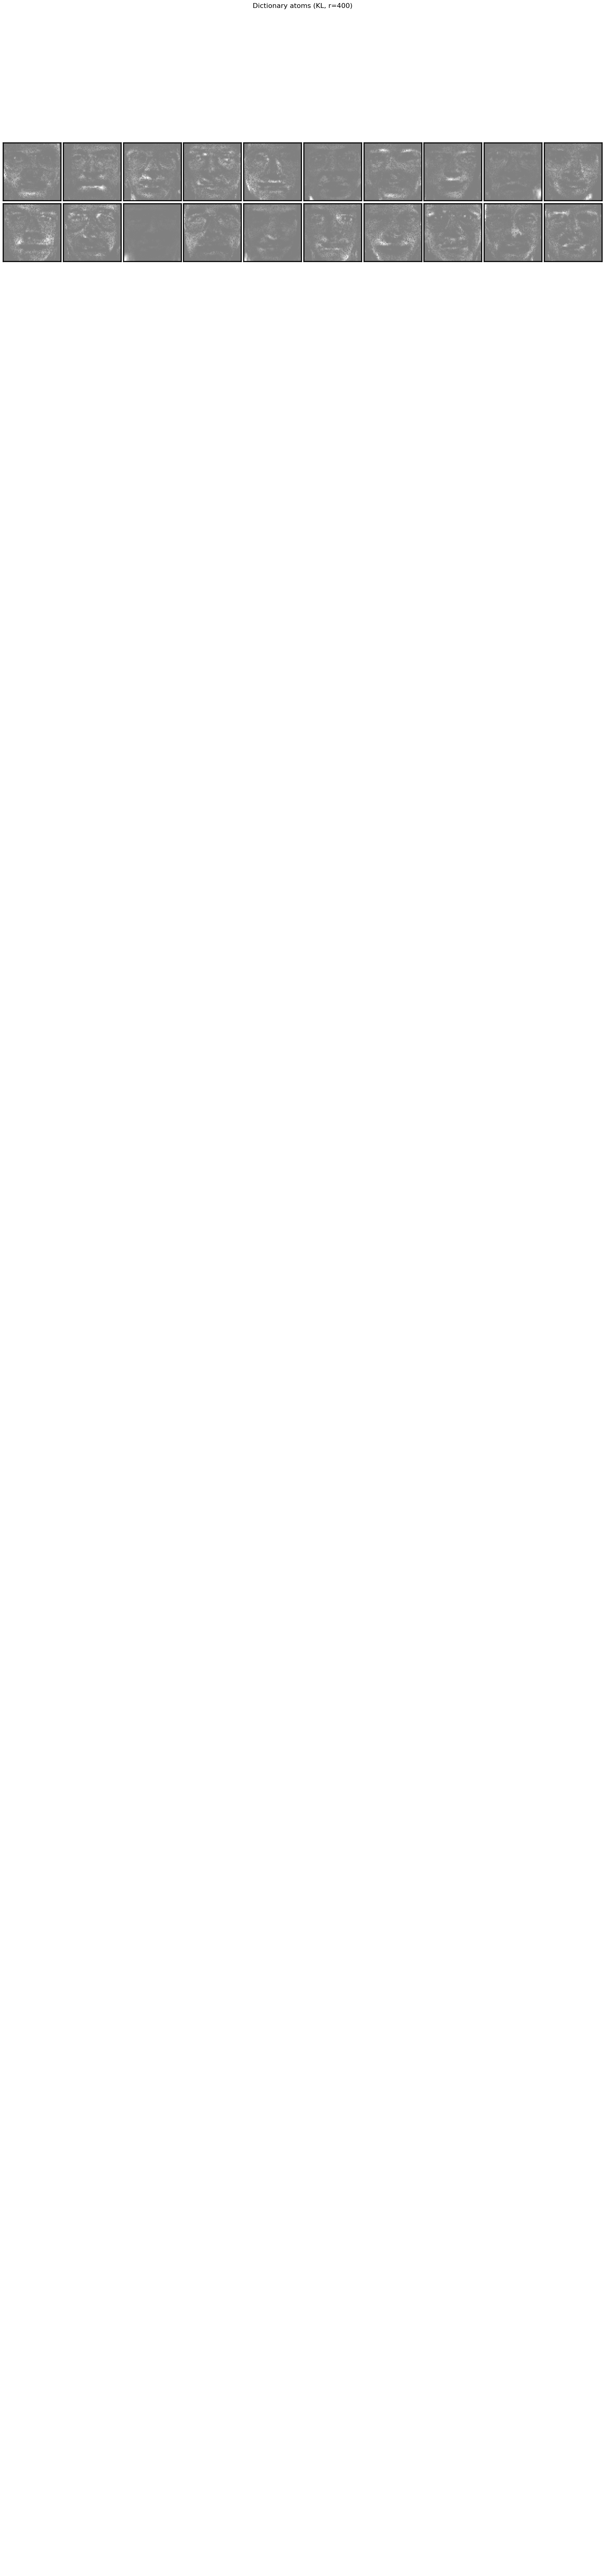

In [6]:
#TODO : plot the atoms of the dictionary for various number of components
number_of_components = [10, 20, 40, 60, 100, 150, 200, 400]

def plot_atoms(D, title):
    r = D.shape[1]
    ncol = min(r, 10)
    nrow = int(np.ceil(r / ncol))
    plot_gallery(title=title, images=D.T[:20], image_shape=image_shape, nrow=nrow, ncol=ncol)

for n_components in number_of_components:
    for loss in ["Frobenius", "KL"]:
        mynmf = MYNMF(n_components=n_components, loss = loss)
        mynmf.fit_transform(data = faces.T)
        plot_atoms(mynmf.D_, f"Dictionary atoms ({loss}, r={n_components})")


**Comments:**
- Small r (10, 20): each atom looks like a whole face, often close to one specific person of the dataset (glasses, beard...). With so few atoms, each one has to explain a large part of the images, this explains why it uses many faces features. 
- Larger r (100 and above): the atoms become more localized and sparser: some of them only activate on the mouth, the nose... This is the parts based representation expected from NMF: since coefficients are non-negative, faces are built by adding parts, never by subtracting them.
- Frobenius vs KL: for r = 20 the atoms are almost identical one by one, because both algorithms start from the same random initialization and converge to close solutions.

Please note that only the first 20 elements of the dictionaries were plotted to keep the jupyter notebook light and readable enough. 
 

### Study of the clustering for the Frobenius distance with 30 components

Now, we are going to clusterise the images in r different classes. First, we start by normalizing the norm of the dictionary elements, so that the euclidian norm = 1, and we multiply the associated row in the S matrix to preserve the factorization DS = X. Then, we find the highest coefficient for each image, and we use the index of the maximum as clustering label.

#### Label

In [14]:
#TODO : Study the clustering
data = faces.T
mynmf = MYNMF(n_components=30)
mynmf.fit_transform(data = data)
labels = mynmf.predict_label(data)

In [15]:
np.where(labels == 6)

(array([  0,  11,  22,  96, 144, 151, 153, 157, 161, 182, 200, 215, 251,
        257, 295, 320, 357, 371]),)

In [16]:
len(labels)

400

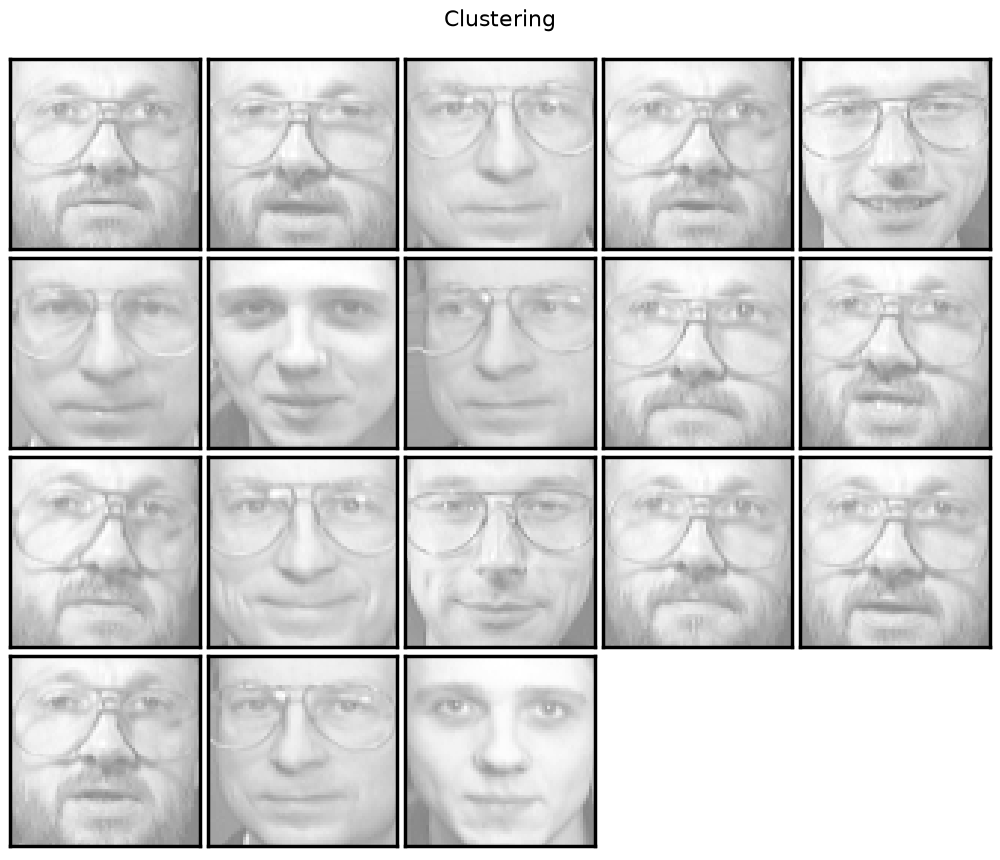

In [17]:
mask = (labels == 6)

n_images = len(faces[mask])
ncols = 5
nrows = n_images//5 + 1
fig, axes = plt.subplots(nrows, ncols, figsize=(2. * ncols, 2.26 * nrows))
fig.suptitle("Clustering", size=16)

axes_for_display = axes.flatten()[:n_images]
axes_to_blank = axes.flatten()[n_images:]

for idx, comp in enumerate(faces[mask]):
    ax = axes_for_display[idx]
    vmax = max(comp.max(), -comp.min())
    ax.imshow(comp.reshape(image_shape), cmap=plt.cm.gray,
                interpolation='nearest',
                vmin=-vmax, vmax=vmax)
    ax.set(xticks=(),
            yticks=())
    
for ax in axes_to_blank:
    ax.axis('off')

fig.tight_layout()
fig.subplots_adjust(0.01, 0.05, 0.99, 0.93, 0.04, 0.)  # insert space below the suptitle



**Comments:** The model is able to cluster together similar faces. Indeed, after a few visualizations, we noticed that faces belonging to one cluster genereally shared some features: similar angle, glasses or no glasses... The same people captured with different angles are often clustered together. 
For example, in the 6th cluster displayed above, we can see that the majority of faces have glasses. The same man with glasses and the beard (first pictures) also appears 9 times in the cluster.  

## Second application 

Import the 20newsgroups dataset that contains a collection of ~18,000 newsgroup documents from 20 different newsgroups.

Model the topics present in a subsample with *scikit-learn's* NMF. Print the most common words of each topic. 

Discuss.

In [18]:
from sklearn.datasets import fetch_20newsgroups_vectorized
from sklearn.decomposition import NMF

#TODO

newsgroups = fetch_20newsgroups_vectorized() # defaults: already selects a train subset of the dataset

X = newsgroups.data
X

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1787565 stored elements and shape (11314, 130107)>

In [19]:
nmf = NMF(n_components=20, max_iter=400)
W = nmf.fit_transform(X)
H = nmf.components_

In [20]:
print(W.shape)
print(H.shape)

(11314, 20)
(20, 130107)


In [21]:
n_top_words = 10
feature_names = newsgroups.feature_names

for topic_idx, topic in enumerate(H):
    top_indices = topic.argsort()[-n_top_words:][::-1]
    words = [feature_names[i] for i in top_indices]
    print(f"Topic {topic_idx + 1}: {', '.join(words)}")

Topic 1: the, from, at, by, with, same, was, were, into, first
Topic 2: is, not, there, what, as, which, an, but, one, can
Topic 3: edu, university, organization, subject, article, lines, posting, host, nntp, re
Topic 4: of, by, one, as, university, who, science, all, with, some
Topic 5: to, do, get, want, how, use, reply, we, way, them
Topic 6: and, with, all, from, other, will, more, at, them, two
Topic 7: in, article, writes, an, re, there, from, ca, vs, no
Topic 8: com, re, writes, organization, subject, lines, from, article, posting, nntp
Topic 9: you, your, if, re, do, can, what, don, have, me
Topic 10: it, but, just, was, like, don, so, my, if, can
Topic 11: for, sale, looking, new, at, 00, will, software, lines, am
Topic 12: that, not, the, we, for, people, god, believe, say, one
Topic 13: from, lines, subject, organization, university, posting, host, nntp, ca, thanks
Topic 14: was, he, his, but, had, they, him, who, were, at
Topic 15: have, with, my, but, any, me, problem, wou

**Comments:** Most of the selected words are short words, that are very frequent ("the", "is"...). However, the model is able to identify relevant words belonging to the same topic. For example, Topic 3 contains words related to education (edu, university, organization, subject...).

Cleaning the original dataset to remove the most common words could improve the quality of the retrieved words, because these short words often don't bring any relevant information.